# x50 データの前処理から予測まで（通常の回帰: 全種類を1つのモデルで、GroupKFold、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-26
- **目的**: `007_pipeline_x50_global.ipynb`（時系列のグローバルモデル。目的変数のラグを使う再帰予測）と同じデータ・同じ
  処理順で、**時系列として扱わず、通常の回帰タスク**として学習・予測した場合を確かめる。全種類（`Y_cat` = Y1〜Y10）を
  1つのモデルで学習し、テスト期間（2025年）を予測、評価（MAE）、SHAP によるモデル解釈を行い、007・004 と比べる。
- **007 との違い**
  - 目的変数のラグ・移動平均・前日比は使わない（テスト期間の値が分からず、再帰予測もしないため作れない）。
    特徴量は「系列ID（`Y_cat`）+ 日付の特徴量 + 説明変数」だけで、各行はその行の特徴量だけから予測する。
  - CV は **GroupKFold**（グループ = 年月）。同じ月の行は、学習と検証に分かれない。
  - 目的変数は元の尺度（`Y_raw`）のまま学習・予測する（007 は対数）。
- **入力**（ダミー。`scripts/generate_dummy_x50.py` で作成）
  - 学習: `data/synthetic/x50/dummy_x50_train.csv`（2022-01-01〜2024-12-31）
  - テスト: `data/synthetic/x50/dummy_x50_test.csv`（2025-01-01〜2025-12-31、目的変数の値なし）
  - 正解: `data/synthetic/x50/dummy_x50_test_answer.csv`（列 `date`, `Y_cat`, `Y`。予測の評価だけに使う）
- **出力**
  - 前処理済みの CSV（long 型）: `data/processed/x50/x50_train_features.csv`, `x50_test_features.csv`（007 と同じもの）
  - `outputs/experiments/x50_regression_{モデル名}/{実行日時}/`（予測・MAE の表・図・SHAP・ログ）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **欠損**: 目的変数・説明変数に、散発的な欠損と連続した欠損がある（学習・テストの両方）。欠損は埋めず、
  目的変数が欠損の行は学習・評価から除く（「リークを防ぐための決まり」の「欠損」）
- **スクリプト版**: 後半の処理は `scripts/train_predict_x50_regression.py`（CLI）と同じ関数を使う。このノートブックは
  `scripts/` を import せず、同じ関数をノートブック内（「関数の定義」）で定義している

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理（前半） | 値を学習する前処理（べき変換の λ・スケーリングの中央値と四分位範囲・経過日数の基準日・べき変換する列の判定）は学習データだけで fit し、テストデータには `transform` だけをかける。系列IDの整数化（`PandasOrdinalEncoder`）だけは、後半で CV の各 fold の学習側で fit する | 4. 前処理のリークの確認 / `modeling` の Pipeline |
| 目的変数の特徴量 | 前半の CSV には 007 と同じく目的変数のラグ等（`Y_lag_*`）も出力するが、後半では使わない（テスト期間には作れないため） | 6. 学習用データとリークの確認（`prepare`） |
| 入力（後半） | 前処理済みのテストデータに、目的変数（`Y`・`Y_raw`）も、その特徴量（`Y_lag_*`）も無いこと | 5. 読み込み（`load_inputs`） |
| 特徴量 | モデルの特徴量は系列ID・日付の特徴量・説明変数だけ。目的変数・そのラグ・日付・グループの列が入っていないこと | 6. 学習用データとリークの確認（`prepare`） |
| CV | GroupKFold（グループ = 年月）。同じ月の行（全種類・全日）は学習と検証に分かれず、各月はちょうど1つの fold の検証に入る。隣り合う日は値が似ている（自己相関）ため、日付や行の単位で分けるより検証が甘くなりにくい | 6. の fold の月の確認 |
| 予測 | 各行の予測は、その行の特徴量だけから行う（他の日・未来の値を使わない） | 予測のリークの確認 |
| 早期終了 | early stopping に使う検証データは各 fold の検証側だけ（007 と同じ）。テスト期間のモデルは、学習データ全体で fold の平均の木の本数で学習し直す | `modeling.trainer` |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | 7. `collect_predictions` |
| 欠損 | 欠損は前後の値で埋めない（補間はその日より後の値を使うため）。目的変数が欠損の行は学習（通常の回帰では欠損の目的変数は学習できない）・評価から除く。説明変数の欠損はモデルに任せる | 6. 学習用データとリークの確認（`prepare`） |

**注意（リークではないが、評価の条件の違い）:** GroupKFold では、検証の月より**後の**月も学習に使う。テストは学習データより
後の2025年なので、CV はテストより楽観的な（誤差が小さい）値になりやすい。時間の流れに沿った評価は 007 の時系列CVで行っている。

In [1]:
import datetime as dt
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.pipeline import Pipeline

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from feature_engineering.datetime_features import (  # noqa: E402
    CyclicalFeaturesEncoder,
    DatetimeFeaturesExtractor,
    ElapsedTimeTransformer,
)
from feature_engineering.numeric import LogTransformer, PandasPowerTransformer  # noqa: E402
from feature_engineering.scaling import PandasRobustScaler  # noqa: E402
from modeling.config import ExperimentConfig, ForecastConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import TargetFeatureBuilder  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.tasks import Task, predict  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

# pandas の表示で列を省略しすぎないようにする
pd.set_option("display.max_columns", 30)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/008_pipeline_x50_regression.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGET_CATS: [Y1, Y2, Y3], DETAIL_TARGET: Y2, N_SPLITS: 4}"
```

In [2]:
# --- 入力・出力（data/ からの相対パス） ---
# いずれも long 型（1行 = 日付 × 目的変数の種類）
RAW_TRAIN_PATH = "synthetic/x50/dummy_x50_train.csv"  # 学習データ（date, Y_cat, Y, X1〜X50）
RAW_TEST_PATH = "synthetic/x50/dummy_x50_test.csv"  # テストデータ（date, Y_cat, X1〜X50）
RAW_ANSWER_PATH = "synthetic/x50/dummy_x50_test_answer.csv"  # テストの正解（None なら評価しない）
FEATURES_DIR = "processed/x50"  # 前処理済みの CSV の出力先（後半の学習の入力になる）

# --- 前処理・特徴量エンジニアリング ---
DATE_COL = "date"  # 日付
CAT_COL = "Y_cat"  # 目的変数の種類（Y1〜Y10。種類ごとに別の系列）
TARGET_COL = "Y"  # 目的変数の値
TARGET_CATS = None  # 予測する種類（None なら学習データの全種類。データに出てくる順）
FEATURE_COLS = None  # 説明変数（None なら日付・種類・目的変数以外の全列）
# 目的変数の特徴量（007 と同じ CSV を出力するために作る。後半の通常の回帰では使わない）
TARGET_LAGS = [1, 2, 3, 7, 14, 28]  # ラグ（日数。1以上）
ROLLING_WINDOWS = [7, 28]  # 前日までの移動平均の窓幅（日数）
# 移動平均に必要な、窓内の観測値（欠損でない値）の数。
# 目的変数に欠損があっても、窓内の観測値だけで平均する（後半の学習でも同じ値を使う）
ROLLING_MIN_PERIODS = 1
RATE_OF_CHANGE = True  # 前日の前日比を加えるか
# 目的変数の変換（"log" または None）。後半の学習も対数で行う（"log" 以外は後半と合わない）
TARGET_TRANSFORM = "log"
TARGET_LOG_OFFSET = 0.0
DATE_COMPONENTS = ["year", "month", "day", "weekday", "week"]  # 日付から取り出す成分
# 学習データの歪度の絶対値がこれを超える説明変数は、べき変換（Yeo-Johnson）で分布を整える
SKEW_THRESHOLD = 1.0

# --- 学習（通常の回帰） ---
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
DETAIL_TARGET = "Y1"  # 詳しい図を表示する種類
N_TRIALS = 0  # Optuna の試行回数（0 ならチューニングしない）
N_SPLITS = 5  # GroupKFold の分割数（グループ = 年月）
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）
# 個別モデル（004 / 006）・時系列のグローバルモデル（005 / 007）の最新の結果と比べるか
COMPARE_WITH_OTHERS = True

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50_regression.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
入力の読み込み・確認と図の部品は、004（`scripts/train_predict_x50.py`）と同じ関数。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

前半の前処理（`Preprocessor` など）は、前半の各節の中で定義する。日付・種類・目的変数の列名（`DATE_COL`・`CAT_COL`・
`TARGET_COL`）と、移動平均に必要な観測値の数（`ROLLING_MIN_PERIODS`。前半の前処理で使う）は、スクリプトでは定数だが、
このノートブックではパラメータのセルで定義する。

### 定数と結果の入れ物

入出力のパス・列名（日付 `date`・種類 `Y_cat`・目的変数 `Y`）（004 と同じ）、GroupKFold のグループの列名（`year_month`）と
分割数の既定値、リークのおそれを表すエラー（`LeakageError`）、読み込んだ入力（`Inputs`）・通常の回帰の結果
（`RegressionRun`）をまとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Y_raw`）


PRED_COL = "pred"  # 種類ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"

logger = logging.getLogger("train_predict_x50_regression")

GROUP_COL = "year_month"  # GroupKFold のグループ（年月。例: 2022-01）

DEFAULT_N_SPLITS = 5  # GroupKFold の分割数


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、目的変数から作った特徴量の定義（列名から読み取る）。

    特徴量は種類（`Y_cat`）ごとに作られているが、列名・定義は全種類で共通。

    Attributes:
        target: 目的変数の列名（`Y`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力（いずれも long 型）。

    Attributes:
        train: 学習データのCSV（選んだ種類の行だけ。日付の昇順、同じ日付の中は種類の順）。
        test: テストデータのCSV（同上）。
        categories: 予測する目的変数の種類（`Y_cat` の値。データに出てくる順）。
        spec: 目的変数の特徴量の定義（全種類で共通）。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全種類のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    categories: list[str]
    spec: TargetFeatureSpec
    exog_cols: list[str]


@dataclass
class RegressionRun:
    """通常の回帰モデルの学習・予測の結果。

    Attributes:
        categories: 目的変数の種類（系列）の並び。
        dataset: 学習用データ一式。
        frame: 学習に使った行の表（`dataset.X` と同じ行順。列 `date`, `Y_cat`, `year_month`, `Y`）。
        result: `run_experiment` の結果。
        predictions: テスト予測（long 型。列 `date`, `Y_cat`, `pred`。正解があれば `actual` も）。
        oof: 学習期間の OOF 予測（long 型。列 `date`, `Y_cat`, `actual`, `pred`, `fold`）。
    """

    categories: list[str]
    dataset: Dataset
    frame: pd.DataFrame
    result: ExperimentResult
    predictions: pd.DataFrame
    oof: pd.DataFrame

In [4]:
# このノートブックでは、前半（1〜4）で作る前処理済みの CSV を後半の入力にする
# （上のセルはスクリプトと同じ既定値。パラメータで指定した出力先に置き換える）
TRAIN_PATH = data_dir() / FEATURES_DIR / "x50_train_features.csv"
TEST_PATH = data_dir() / FEATURES_DIR / "x50_test_features.csv"
ANSWER_PATH = None if RAW_ANSWER_PATH is None else data_dir() / RAW_ANSWER_PATH

### ログ（004 と同じ）

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [5]:
def setup_logging(log_path: Path, level: int = logging.INFO) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    root = logging.getLogger()
    root.setLevel(level)
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    handlers: list[logging.Handler] = [
        logging.FileHandler(log_path, encoding="utf-8"),
        logging.StreamHandler(sys.stdout),
    ]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認（004 と同じ）

long 型の学習データの列から、目的変数の特徴量の定義（ラグ・移動平均・前日比）を読み取り、テストデータに目的変数
（`Y`・`Y_raw`）やその特徴量（`Y_lag_*`）が無いこと・学習とテストで特徴量の列が同じこと・種類ごとに日付が1日刻みで
続いていることを確かめる（`load_inputs`）。行は日付の昇順、同じ日付の中は種類の順に並べる（`sort_long`）。

In [6]:
def category_order(frame: pd.DataFrame) -> list[str]:
    """目的変数の種類（`Y_cat` の値）を、データに出てくる順に返す。"""
    return [str(c) for c in dict.fromkeys(frame[CAT_COL])]


def sort_long(frame: pd.DataFrame, categories: Sequence[str]) -> pd.DataFrame:
    """long 型の表を、日付の昇順・同じ日付の中は種類の順（categories の順）に並べる。"""
    order = {cat: i for i, cat in enumerate(categories)}
    return frame.sort_values(
        [DATE_COL, CAT_COL],
        key=lambda s: s.map(order) if s.name == CAT_COL else s,
        kind="stable",
    ).reset_index(drop=True)


def parse_target_features(columns: Sequence[str], target: str = TARGET_COL) -> TargetFeatureSpec:
    """列名から、目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """種類ごとに、日付が1日刻みで重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    for category, part in frame.groupby(CAT_COL, sort=False):
        gaps = part[DATE_COL].diff().dropna()
        if part[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
            raise ValueError(
                f"{name}（{category}）の日付が1日刻みになっていません（重複または欠け）"
            )


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    categories: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータ（long 型）を読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、目的変数（`Y`・`Y_raw`）も、目的変数から作った特徴量（`Y_lag_*`）も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。予測する種類が両方にある。
        - 種類ごとに1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        categories: 予測する種類（Noneなら学習データの全種類）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path)
    test = read_csv_auto(test_path)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    raw_col = f"{TARGET_COL}{RAW_SUFFIX}"
    for name, frame, required in (
        ("学習", train, [DATE_COL, CAT_COL, TARGET_COL, raw_col]),
        ("テスト", test, [DATE_COL, CAT_COL]),
    ):
        missing = [c for c in required if c not in frame.columns]
        if missing:
            raise ValueError(f"{name}データに列がありません: {missing}")
    # 種類の列（Y_cat）は目的変数の値ではないので除く
    leaked = [
        c
        for c in test.columns
        if c != CAT_COL and (c in (TARGET_COL, raw_col) or c.startswith(f"{TARGET_COL}_"))
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")

    all_categories = category_order(train)
    selected = list(categories) if categories else all_categories
    unknown = [c for c in selected if c not in all_categories]
    if unknown:
        raise ValueError(f"学習データに無い種類です: {unknown}（あるのは {all_categories}）")
    missing_in_test = [c for c in selected if c not in set(test[CAT_COL])]
    if missing_in_test:
        raise ValueError(f"テストデータに無い種類です: {missing_in_test}")

    columns = list(train.columns)
    spec = parse_target_features(columns)
    target_cols = {TARGET_COL, raw_col, *spec.columns}
    exog_cols = [c for c in columns if c not in (DATE_COL, CAT_COL) and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL, CAT_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL, CAT_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    train = sort_long(train[train[CAT_COL].isin(selected)], selected)
    test = sort_long(test[test[CAT_COL].isin(selected)], selected)
    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end = train.groupby(CAT_COL)[DATE_COL].max()
    test_start = test.groupby(CAT_COL)[DATE_COL].min()
    not_next = [c for c in selected if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
    if not_next:
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}"
        )
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train[DATE_COL].max():%Y-%m-%d}",
        f"{test[DATE_COL].min():%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数の種類（%s）: %s", CAT_COL, selected)
    logger.info(
        "特徴量: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "種類ごとに再帰予測で作り直す）,"
        " 日付・説明変数 %d列",
        len(spec.columns),
        spec.lags,
        spec.rolling_windows,
        spec.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, CAT_COL, *exog_cols]],
        categories=selected,
        spec=spec,
        exog_cols=exog_cols,
    )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer

### モデルに渡す表

`model_frames`: 全種類の行を使い、種類の列 `Y_cat` を系列IDとして残す。GroupKFold のグループとして年月（`year_month`）の列を
加え、目的変数は元の尺度（`Y_raw`）にする。CSVにある目的変数の特徴量（`Y_lag_*`）は使わず、目的変数が欠損の行は除く。

In [7]:
def model_frames(inputs: Inputs) -> tuple[pd.DataFrame, pd.DataFrame]:
    """`prepare_dataset` に渡す学習・テストの表を作る（long 型のまま、全種類の行を使う）。

    学習の表は「日付・系列ID（`Y_cat`）・年月（グループ）・日付の特徴量・説明変数・目的変数（元の尺度）」。
    CSVにある目的変数の特徴量（`Y_lag_*`）は使わない（テスト期間には作れないため）。
    目的変数が欠損の行は学習できないため除く。

    Returns:
        (学習の表, テストの表（目的変数なし）)。
    """
    columns = [DATE_COL, CAT_COL, *inputs.exog_cols]
    dates = pd.to_datetime(inputs.train[DATE_COL])
    train = inputs.train[columns].assign(
        **{
            GROUP_COL: dates.dt.strftime("%Y-%m"),
            TARGET_COL: inputs.train[f"{TARGET_COL}{RAW_SUFFIX}"],
        }
    )
    train = train[train[TARGET_COL].notna()]
    test = inputs.test[columns]
    assert TARGET_COL not in test.columns
    return train.reset_index(drop=True), test.reset_index(drop=True)

### 実験設定

通常の回帰（`task: regression`）の `modeling.config.ExperimentConfig` を作る。系列ID（`Y_cat`）の整数化
（`PandasOrdinalEncoder`。CVの fold ごとに学習側で fit）と、年月をグループにした GroupKFold（`cv.method: group`）を含む。
再帰予測の設定（`forecast`）は無い。

In [8]:
def make_config(
    model: str,
    n_series: int,
    n_splits: int = DEFAULT_N_SPLITS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
) -> ExperimentConfig:
    """通常の回帰モデルの実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        n_series: 種類（系列）の数（記録用）。
        n_splits: GroupKFold の分割数。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` / `fold_mean`）。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_regression_{model}",
            # 時系列として扱わない通常の回帰（目的変数のラグ・再帰予測を使わない）
            "task": "regression",
            "data": {
                "train_path": str(TRAIN_PATH),
                "test_path": str(TEST_PATH),
                "target": TARGET_COL,
                # GroupKFold のグループ。日付・グループの列はモデルの特徴量から外す
                "group_col": GROUP_COL,
                "drop_cols": [DATE_COL, GROUP_COL],
            },
            # 系列ID（Y1〜Y10 の文字列）を整数にして、モデルが種類を区別できるようにする。
            # CVの各 fold の学習側だけで fit される
            "features": [
                {
                    "class": "feature_engineering.categorical.PandasOrdinalEncoder",
                    "params": {"variables": [CAT_COL]},
                }
            ],
            # 年月をグループにした GroupKFold（同じ月の行は学習と検証に分かれない）
            "cv": {"method": "group", "n_splits": n_splits},
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True, "max_series": n_series},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: 全種類の学習用データ一式を作り、モデルの特徴量に目的変数・そのラグ・日付・グループの列が無いこと、
  CVの各 fold で同じ年月が学習と検証の両方に入っていないこと（各月はちょうど1つの fold の検証に入ること）を確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で、GroupKFold の CV・テスト予測・誤差評価・SHAP を行う。
- `collect_predictions`: テスト予測と OOF 予測を、日付・種類つきの long 型の表にする（テストの正解は、ここで予測と突き合わせる。
  正解が欠損の行は評価から除く）。

In [9]:
def prepare(config: ExperimentConfig, inputs: Inputs) -> tuple[Dataset, pd.DataFrame]:
    """全種類の学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - モデルの特徴量に、目的変数（`Y`・`Y_raw`）・目的変数の特徴量（`Y_lag_*`）・
          日付・グループの列が無い。
        - CVの各 fold で、同じ年月が学習と検証の両方に入っていない。
          各年月はちょうど1つの fold の検証に入る。
        - テストデータに目的変数が無い。

    Returns:
        (学習用データ一式, 学習に使った行の表（`dataset.X` と同じ行順）)。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    train, test = model_frames(inputs)
    n_dropped = len(inputs.train) - len(train)
    dataset = prepare_dataset(config, train, test)

    target = TARGET_COL
    leaked = [
        c
        for c in dataset.X.columns
        if c in (target, f"{target}{RAW_SUFFIX}", DATE_COL, GROUP_COL)
        or c.startswith(f"{target}_lag_")
    ]
    if leaked:
        raise LeakageError(f"モデルの特徴量に目的変数・日付・グループの列があります: {leaked}")

    groups = train[GROUP_COL].to_numpy()
    validated: list[str] = []
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        shared = set(groups[train_idx]) & set(groups[valid_idx])
        if shared:
            raise LeakageError(f"fold {i}: 同じ年月が学習と検証の両方にあります: {shared}")
        months = sorted(set(groups[valid_idx]))
        validated += months
        logger.info(
            "fold %d: 検証 %d か月（%s）・%d行 / 学習 %d行",
            i,
            len(months),
            ", ".join(months),
            len(valid_idx),
            len(train_idx),
        )
    if sorted(validated) != sorted(set(groups)):
        raise LeakageError("検証に入らない年月、または複数の fold の検証に入る年月があります")
    if dataset.X_test is None or target in dataset.X_test.columns:
        raise LeakageError("テストデータに目的変数があります（またはテストデータがありません）")
    logger.info(
        "学習データ（long 型）: %d行（目的変数が欠損の %d行を除く）,"
        " 特徴量 %d列（系列ID・日付・説明変数）",
        len(dataset.X),
        n_dropped,
        dataset.X.shape[1],
    )
    return dataset, train


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """GroupKFold の CV 学習・テスト予測・誤差評価・SHAP を `run_experiment` で行う。"""
    logger.info(
        "学習開始: 通常の回帰モデル=%s, CV=GroupKFold（%d分割、グループ=%s）,"
        " チューニング=%s, テスト予測=%s",
        config.model.name,
        config.cv.n_splits,
        GROUP_COL,
        f"{config.tuning.n_trials}試行" if config.tuning.enabled else "なし",
        config.test_prediction,
    )
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"model_type": "regression", **(extra_tags or {})},
    )
    cv = result.cv_result
    logger.info(
        "学習終了（%.1f秒）: CV MAE fold別 %s / OOF %.4f。出力 %s",
        time.perf_counter() - start,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        shown(result.output_dir),
    )
    if result.tuning_result is not None:
        logger.info("チューニングの最良パラメータ: %s", result.tuning_result.best_params)
    return result


def collect_predictions(
    categories: list[str],
    dataset: Dataset,
    frame: pd.DataFrame,
    test: pd.DataFrame,
    result: ExperimentResult,
    answer: pd.DataFrame | None,
) -> RegressionRun:
    """テスト予測と OOF 予測を、日付・種類つきの long 型の表にする（正解があれば付ける）。

    Args:
        categories: 種類の並び。
        dataset: 学習用データ一式。
        frame: `prepare` が返した学習の表（`dataset.X` と同じ行順）。
        test: テストデータ（`dataset.X_test` と同じ行順。`inputs.test`）。
        result: `run_experiment` の結果。
        answer: テストの正解（Noneなら付けない）。正解の値が欠損の行は評価から除く。

    Raises:
        ValueError: 正解ファイルに、テスト期間の一部の日付・種類の行が無い場合。
    """
    cv = result.cv_result
    assert cv.test_pred is not None
    keys = [DATE_COL, CAT_COL]
    predictions = test[keys].reset_index(drop=True).assign(**{PRED_COL: cv.test_pred})
    if answer is not None:
        # 正解（long 型）はテスト予測が終わった後にだけ使う
        actual = answer[[*keys, TARGET_COL]].rename(columns={TARGET_COL: ACTUAL_COL})
        predictions = predictions.merge(actual, on=keys, how="left", validate="1:1", indicator=True)
        if (predictions["_merge"] != "both").any():
            raise ValueError("正解ファイルに、テスト期間の一部の日付・種類がありません")
        predictions = predictions.drop(columns="_merge")
    oof = (
        frame[keys]
        .reset_index(drop=True)
        .assign(**{ACTUAL_COL: dataset.y, PRED_COL: cv.oof_pred, "fold": cv.fold_ids})
    )
    return RegressionRun(categories, dataset, frame, result, predictions, oof)

### 図の部品（004 と同じ）

図の保存（`save_figure`）、種類ごとの相対MAEの棒グラフ（`plot_summary_mae`）、
種類ごとの SHAP 重要度のヒートマップ（`plot_shap_overview`）。

In [10]:
def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """種類ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary[CAT_COL])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 種類ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "種類ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。種類ごとに合計1）")
    ax.set_title(f"{title}: 種類ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig

### 要約と図

種類ごとの MAE・相対MAE の表、全種類のテスト予測（long 型）、系列ごとの学習結果（OOF 予測）・テスト結果の図、
SHAP 値を行の系列で分けた種類ごとの重要度を作り、出力ディレクトリと MLflow に保存する（`save_outputs`）。

In [11]:
def summary_frame(run: RegressionRun) -> pd.DataFrame:
    """種類ごとの MAE をまとめた表（`train_predict_x50.summary_frame` と同じ列）。

    正解が欠損の行は MAE・相対MAE の計算から除く。
    """
    mae = get_metric("mae")
    actual_col, pred_col = ACTUAL_COL, PRED_COL
    rows = []
    for category in run.categories:
        oof = run.oof[(run.oof[CAT_COL] == category) & (run.oof["fold"] >= 0)]
        cv_mae = mae(oof[actual_col].to_numpy(), oof[pred_col].to_numpy())
        row: dict[str, object] = {
            CAT_COL: category,
            "cv_oof_mae": cv_mae,
            "cv_relative_mae": cv_mae / float(oof[actual_col].mean()),
        }
        if actual_col in run.predictions.columns:
            test = run.predictions[run.predictions[CAT_COL] == category]
            test_mae = mae(test[actual_col].to_numpy(), test[pred_col].to_numpy())
            row["test_mae"] = test_mae
            row["test_relative_mae"] = test_mae / float(test[actual_col].mean())
        rows.append(row)
    return pd.DataFrame(rows)


def plot_training_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """学習結果: 系列ごとに、学習期間の実測値と OOF 予測（GroupKFold の検証の予測）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    mae = get_metric("mae")
    date_col, actual_col, pred_col = DATE_COL, ACTUAL_COL, PRED_COL
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.oof[run.oof[CAT_COL] == category]
        ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.7, label="実測")
        ax.plot(part[date_col], part[pred_col], color="C3", linewidth=0.9, label="OOF予測")
        score = mae(part[actual_col].to_numpy(), part[pred_col].to_numpy())
        ax.set_title(f"{category}（CV MAE={score:.2f}）")
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: 学習期間の実測値と、OOF 予測（系列ごと）")
    add_caption(
        fig,
        f"1つのモデルで全種類を学習。各月の予測は、その月を含まない fold のモデルによる"
        f"（GroupKFold、グループ={GROUP_COL}）。目的変数が欠損の日は除く。",
    )
    return fig


def plot_test_overview(run: RegressionRun, title: str, ncols: int = 2) -> plt.Figure:
    """テスト結果: 系列ごとに、テスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(run.categories) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    date_col, actual_col, pred_col = DATE_COL, ACTUAL_COL, PRED_COL
    has_answer = actual_col in run.predictions.columns
    mae = get_metric("mae")
    for ax, category in zip(axes.flat, run.categories, strict=False):
        part = run.predictions[run.predictions[CAT_COL] == category]
        label = category
        if has_answer:
            ax.plot(part[date_col], part[actual_col], color="black", linewidth=0.8, label="実測")
            label += f"（MAE={mae(part[actual_col].to_numpy(), part[pred_col].to_numpy()):.2f}）"
        ax.plot(part[date_col], part[pred_col], color="C3", linewidth=1.2, label="予測")
        ax.set_title(label)
    for ax in list(axes.flat)[len(run.categories) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（系列ごと）")
    return fig


def shap_importance_table(run: RegressionRun) -> pd.DataFrame:
    """系列ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 種類の表にする。

    OOF SHAP 値を行の系列（種類）で分けて平均する。系列ID（`Y_cat`）は `系列ID` に名前を変える。
    """
    values = pd.read_parquet(run.result.output_dir / "shap" / "shap_values.parquet")
    series = run.frame[CAT_COL].to_numpy()[values.pop("row").to_numpy()]
    rename = {c: "系列ID" if c == CAT_COL else c for c in values.columns}
    importance = values.abs().groupby(series).mean().T.rename(index=rename)
    importance = importance[[c for c in run.categories if c in importance.columns]]
    return importance / importance.sum()


def save_outputs(
    run: RegressionRun, model: str, tracker_enabled: bool, log_path: Path | None = None
) -> pd.DataFrame:
    """要約の表・予測・図・ログを実験の出力ディレクトリに保存し、MLflow の同じ run にも記録する。"""
    out = run.result.output_dir
    title = f"x50_regression_{model}"
    summary = summary_frame(run)
    paths = [ensure_parent_dir(out / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(out / "test_predictions.csv")
    run.predictions.to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(out / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(run)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = out / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_training_overview(run, title), figures / "training_overview.png"))
    paths.append(save_figure(plot_test_overview(run, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    message = f"要約: CV 相対MAE の平均 {float(summary['cv_relative_mae'].mean()):.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d種類）。表: %s", message, len(run.categories), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, out / "run.log")))

    # run_experiment のrun（終了済み）に、種類ごとの指標と追加の出力を記録する
    if tracker_enabled and run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        metrics = {"mean_cv_relative_mae": float(summary["cv_relative_mae"].mean())}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row[CAT_COL]}"] = float(row["cv_oof_mae"])
            if "test_mae" in row:
                metrics[f"test_mae_{row[CAT_COL]}"] = float(row["test_mae"])
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        for key, value in metrics.items():
            client.log_metric(run.result.run_id, key, value)
        for path in paths:
            client.log_artifact(run.result.run_id, str(path), artifact_path="summary")
        logger.info("MLflow に記録: run_id=%s", run.result.run_id)
    return summary

In [12]:
# ログを画面とファイルの両方に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"pipeline_x50_regression_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(outputs_dir() / "logs" / log_name)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/pipeline_x50_regression_lightgbm_20261026_233212_notebook.log


# 前半: 前処理・特徴量エンジニアリング

`003_feature_engineering_x50.ipynb` と同じ処理。long 型の生データ（学習・テスト）を読み込み、目的変数・日付・説明変数の
それぞれに `src/feature_engineering` の前処理をかけて、前処理済みの CSV（long 型）を出力する。学習が必要な前処理は学習データ
だけで fit する。目的変数のラグ・移動平均・前日比も 007 と同じく作るが、後半の通常の回帰では使わない（テスト期間には作れないため）。

In [13]:
train_path = data_dir() / RAW_TRAIN_PATH
test_path = data_dir() / RAW_TEST_PATH
output_dir = data_dir() / FEATURES_DIR
# 出力先が生データ（data/raw・data/external）でないことを確かめる（生データは書き換えない）
for immutable in ("raw", "external"):
    if output_dir.resolve().is_relative_to((data_dir() / immutable).resolve()):
        raise ValueError(f"data/{immutable} には書き込めません: {output_dir}")

# 目的変数の特徴量の定義（学習データ・再帰予測の両方で同じものを使う）。
# 種類（Y_cat）ごとに作る。ラグは1日以上前、移動平均・前日比は前日のラグ列から作るため、
# 当日の値を含まない
builder = TargetFeatureBuilder(
    TARGET_COL,
    DATE_COL,
    ForecastConfig(
        series_col=CAT_COL,
        lags=TARGET_LAGS,
        rolling_windows=ROLLING_WINDOWS,
        rolling_min_periods=ROLLING_MIN_PERIODS,
        rate_of_change=RATE_OF_CHANGE,
    ),
)
target_feature_cols = builder.feature_names

print(f"入力（学習）: {shown(train_path)}")
print(f"入力（テスト）: {shown(test_path)}")
print(f"前処理済みの CSV の出力先: {shown(output_dir)}")
print(f"目的変数の特徴量（種類ごとに作る）: {target_feature_cols}")
print(f"再帰予測で必要な過去の日数: {builder.lookback}")

入力（学習）: data/synthetic/x50/dummy_x50_train.csv
入力（テスト）: data/synthetic/x50/dummy_x50_test.csv
前処理済みの CSV の出力先: data/processed/x50
目的変数の特徴量（種類ごとに作る）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']
再帰予測で必要な過去の日数: 28


## 1. 読み込みと確認

`util.csv_io.read_csv_auto` で読み込む（文字コードの判定・日付列の変換を自動で行う）。
行を「日付の昇順、同じ日付の中は種類の順」に並べ、種類ごとに 1行 = 1日か（重複・欠けが無いか）、
テストデータが学習データの翌日から続いているかを確かめる
（`sort_long`・`check_daily` は「関数の定義」で定義したもの）。目的変数・説明変数の欠損の状況（割合と、最も長い連続した
欠損の日数）も確かめる。

In [14]:
train_raw = read_csv_auto(train_path)
test_raw = read_csv_auto(test_path)
for name, frame, required in (
    ("学習データ", train_raw, [DATE_COL, CAT_COL, TARGET_COL]),
    ("テストデータ", test_raw, [DATE_COL, CAT_COL]),
):
    missing = [c for c in required if c not in frame.columns]
    if missing:
        raise ValueError(f"{name}に列がありません: {missing}")
if TARGET_COL in test_raw.columns:
    # テスト期間の目的変数の値は予測時点で分からないので、あっても使わない
    print(f"テストデータの {TARGET_COL} 列は使わないため外します")
    test_raw = test_raw.drop(columns=TARGET_COL)

# 予測する種類（データに出てくる順）
cats = TARGET_CATS or list(dict.fromkeys(train_raw[CAT_COL]))
missing_cats = [
    c for c in cats if c not in set(train_raw[CAT_COL]) or c not in set(test_raw[CAT_COL])
]
if missing_cats:
    raise ValueError(f"学習データ・テストデータの両方にない種類があります: {missing_cats}")

excluded = {DATE_COL, CAT_COL, TARGET_COL}
feature_cols = FEATURE_COLS or [c for c in train_raw.columns if c not in excluded]
missing_in_test = [c for c in feature_cols if c not in test_raw.columns]
if missing_in_test:
    raise ValueError(f"テストデータに説明変数がありません: {missing_in_test}")
train_raw = sort_long(
    train_raw.loc[train_raw[CAT_COL].isin(cats), [DATE_COL, CAT_COL, TARGET_COL, *feature_cols]],
    cats,
)
test_raw = sort_long(
    test_raw.loc[test_raw[CAT_COL].isin(cats), [DATE_COL, CAT_COL, *feature_cols]], cats
)

check_daily(train_raw, "学習データ")
check_daily(test_raw, "テストデータ")
train_end = train_raw.groupby(CAT_COL)[DATE_COL].max()
test_start = test_raw.groupby(CAT_COL)[DATE_COL].min()
not_next = [c for c in cats if test_start[c] != train_end[c] + pd.Timedelta(days=1)]
if not_next:
    raise ValueError(f"テストデータが学習データの翌日から始まっていない種類があります: {not_next}")

for name, frame in (("学習", train_raw), ("テスト", test_raw)):
    dates = frame[DATE_COL]
    n_missing_cols = int((frame.isna().sum() > 0).sum())
    n_days, n_cats = dates.nunique(), frame[CAT_COL].nunique()
    print(
        f"{name}: {len(frame)}行 = {n_days}日 × {n_cats}種類, {frame.shape[1]}列"
        f"（{dates.min():%Y-%m-%d}〜{dates.max():%Y-%m-%d}） 欠損のある列: {n_missing_cols}"
    )
print(f"種類: {cats}")


def longest_run(missing: pd.Series) -> int:
    """欠損（True）が連続する最長の日数。"""
    runs = missing.ne(missing.shift()).cumsum()
    return int(missing.groupby(runs).sum().max()) if missing.any() else 0


# 目的変数の欠損（種類ごと）。説明変数は日付ごとの値なので、1つの種類の行で数える
target_by_cat = train_raw.groupby(CAT_COL, sort=False)[TARGET_COL]
target_missing = pd.DataFrame(
    {
        "学習の欠損率": target_by_cat.apply(lambda s: s.isna().mean()),
        "最長の連続欠損の日数": target_by_cat.apply(lambda s: longest_run(s.isna())),
    }
)
one_cat = train_raw[train_raw[CAT_COL] == cats[0]]
one_cat_test = test_raw[test_raw[CAT_COL] == cats[0]]
feature_missing = pd.DataFrame(
    {
        "学習の欠損率": one_cat[feature_cols].isna().mean(),
        "テストの欠損率": one_cat_test[feature_cols].isna().mean(),
        "学習の最長の連続欠損の日数": [longest_run(one_cat[c].isna()) for c in feature_cols],
    }
)
print("目的変数の欠損（学習データ。種類ごと）:")
display(target_missing.round(3).T)
print("説明変数の欠損（欠損率の大きい順に10列）:")
display(feature_missing.sort_values("学習の欠損率", ascending=False).head(10).round(3))
# 種類ごとの水準・ばらつき（尺度が大きく違うので、MAE は種類ごとに比べる）
train_raw.groupby(CAT_COL, sort=False)[TARGET_COL].describe()[["mean", "std", "min", "max"]].round(
    2
)

学習: 10960行 = 1096日 × 10種類, 53列（2022-01-01〜2024-12-31） 欠損のある列: 51
テスト: 3650行 = 365日 × 10種類, 52列（2025-01-01〜2025-12-31） 欠損のある列: 50
種類: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
目的変数の欠損（学習データ。種類ごと）:


Y_cat,Y1,Y2,Y3,Y4,Y5,Y6,Y7,Y8,Y9,Y10
学習の欠損率,0.047,0.055,0.058,0.054,0.047,0.063,0.043,0.053,0.063,0.064
最長の連続欠損の日数,15.000,28.000,22.000,32.000,21.000,34.000,31.000,33.000,26.000,30.000


説明変数の欠損（欠損率の大きい順に10列）:


,学習の欠損率,テストの欠損率,学習の最長の連続欠損の日数
X24,0.057,0.099,27
X42,0.054,0.093,28
X8,0.050,0.011,30
X2,0.048,0.068,28
X7,0.048,0.008,26
X4,0.047,0.052,26
X48,0.047,0.036,28
X25,0.045,0.022,5
X13,0.045,0.055,31
X50,0.043,0.005,30


,mean,std,min,max
Y_cat,,,,
Y1,59.78,13.43,21.32,94.80
Y2,86.32,14.02,46.13,132.19
Y3,79.48,12.23,45.05,108.75
Y4,30.08,3.66,19.39,40.90
Y5,77.87,12.29,46.62,123.19
Y6,150.09,29.66,72.83,223.38
Y7,174.69,21.36,111.80,232.21
Y8,187.71,36.23,98.79,277.43
Y9,139.86,25.05,62.79,214.24


## 2. 前処理の定義

各変数への前処理は次のとおり。学習が必要なもの（★）は学習データだけで fit する。

| 対象 | 前処理 | 作られる列 | 学習データ | テストデータ |
|---|---|---|---|---|
| 目的変数 | `feature_engineering.numeric.LogTransformer`（`TARGET_TRANSFORM="log"`） | `Y`（変換後。元の値は `Y_raw`） | ○ | （目的変数なし） |
| 目的変数 | `modeling.forecasting.TargetFeatureBuilder`（`Y_cat` ごと。内部で `feature_engineering.time_series` のラグ・移動平均・変化率） | `Y_lag_{n}`, `Y_lag_1_ma_{w}`, `Y_lag_1_roc_1` | ○ | **再帰予測の中で作る** |
| 日付 | `datetime_features.DatetimeFeaturesExtractor` | `date_year`, `date_month`, ... | ○ | ○ |
| 日付 | `datetime_features.CyclicalFeaturesEncoder`（月=12, 曜日=7） | `date_month_sin/cos`, `date_weekday_sin/cos` | ○ | ○ |
| 日付 | ★ `datetime_features.ElapsedTimeTransformer`（基準日 = 学習データの初日） | `date_elapsed_days` | ○ | ○ |
| 説明変数 | ★ `numeric.PandasPowerTransformer`（学習データで歪度が大きい列だけ） | 同じ列名で置き換え | ○ | ○ |
| 説明変数 | ★ `scaling.PandasRobustScaler` | 同じ列名で置き換え | ○ | ○ |

欠損はどの前処理でも埋めない（欠損のまま変換し、`Y` が欠損なら `Y_raw` も欠損）。べき変換・スケーリングの値は、
学習データの欠損でない値から求める。目的変数のラグ・移動平均は欠損のまま作り、移動平均は窓内の観測値だけで平均する
（`ROLLING_MIN_PERIODS`）。

学習データで fit した前処理は `Preprocessor` にまとめ、テストデータには同じものの `transform` だけをかける。
long 型では説明変数の値が種類の数だけ繰り返されるが、全ての日付が同じ回数ずつ繰り返されるため、
学習する値（分位数・歪度・λ）は日付ごとの値で計算した場合と同じになる。

In [15]:
class Preprocessor:
    """目的変数の変換・日付の特徴量・説明変数の変換をまとめた前処理（学習データだけで fit する）。

    目的変数のラグ・移動平均は含まない
    （学習データでは `TargetFeatureBuilder.build`、テスト期間では再帰予測で作る）。

    Attributes:
        target_transformer: 目的変数の変換（変換しないならNone）。
        skewed: べき変換する説明変数（学習データの歪度で判定）。
        stateful: fit済みの、学習が必要な前処理（経過日数・べき変換・スケーリング）。
    """

    def fit(self, train: pd.DataFrame) -> "Preprocessor":
        """学習データで、変換の対象と値を決める。"""
        self.target_transformer = None
        if TARGET_TRANSFORM == "log":
            self.target_transformer = LogTransformer(TARGET_COL, offset=TARGET_LOG_OFFSET).fit(
                train
            )
        elif TARGET_TRANSFORM is not None:
            raise ValueError(f"未対応の TARGET_TRANSFORM です: {TARGET_TRANSFORM}")
        dated = self._date_features(train)
        self.skewed = [c for c in feature_cols if abs(dated[c].skew()) > SKEW_THRESHOLD]
        steps: list[tuple[str, object]] = [
            ("elapsed", ElapsedTimeTransformer(DATE_COL, unit="days"))
        ]
        if self.skewed:
            steps.append(("power", PandasPowerTransformer(self.skewed, method="yeo-johnson")))
        steps.append(("scale", PandasRobustScaler(feature_cols)))
        self.stateful = Pipeline(steps).fit(dated)
        return self

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """学習済みの値で変換する（各行の値だけから計算するので、行どうしは影響し合わない）。"""
        frame = frame.copy()
        if TARGET_COL in frame.columns:
            # 評価・出力用に元の値を残してから変換する
            position = frame.columns.get_loc(TARGET_COL) + 1
            frame.insert(position, f"{TARGET_COL}_raw", frame[TARGET_COL])
            if self.target_transformer is not None:
                frame = self.target_transformer.transform(frame)
        return self.stateful.transform(self._date_features(frame))

    def inverse_target(self, values: np.ndarray) -> np.ndarray:
        """モデルの尺度の目的変数を、元の尺度に戻す。"""
        if self.target_transformer is None:
            return values
        restored = self.target_transformer.inverse_transform(pd.DataFrame({TARGET_COL: values}))
        return restored[TARGET_COL].to_numpy(dtype=float)

    @staticmethod
    def _date_features(frame: pd.DataFrame) -> pd.DataFrame:
        """日付の成分と周期特徴量を加える（各行の日付だけから作る。学習は不要）。"""
        frame = DatetimeFeaturesExtractor(DATE_COL, components=DATE_COMPONENTS).fit_transform(frame)
        if "month" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_month", period=12).fit_transform(frame)
        if "weekday" in DATE_COMPONENTS:
            frame = CyclicalFeaturesEncoder(f"{DATE_COL}_weekday", period=7).fit_transform(frame)
        return frame


def build_train_features(prep: Preprocessor, train: pd.DataFrame) -> pd.DataFrame:
    """学習データの前処理結果に、目的変数のラグ・移動平均を加える（種類ごとに、過去の実測値だけを使う）。

    各種類の先頭 `builder.lookback` 日（過去の日数が足りない日）は除く。
    目的変数や特徴量が欠損の行は残す
    （行を消すと1行 = 1日の前提が崩れ、再帰予測の履歴にも使えなくなるため）。
    """
    features = builder.build(prep.transform(train))
    # 種類ごとの、日付の順の位置（行は日付の昇順に並んでいる）
    position = features.groupby(CAT_COL, sort=False).cumcount()
    return features[position >= builder.lookback].reset_index(drop=True)

## 3. 前処理の実行と出力

In [16]:
prep = Preprocessor().fit(train_raw)
# 学習データ全体（先頭行も含む）の前処理結果。再帰予測の履歴として使う
train_prep = prep.transform(train_raw)
train_features = build_train_features(prep, train_raw)
test_features = prep.transform(test_raw)

date_feature_cols = [c for c in test_features.columns if c.startswith(f"{DATE_COL}_")]
# 種類ごとのモデルの特徴量（自身のラグ・移動平均 + 日付 + 説明変数。種類の列は使わない）
model_feature_cols = [*target_feature_cols, *date_feature_cols, *feature_cols]
n_dropped_days = (len(train_raw) - len(train_features)) // len(cats)
print(f"学習データ: {len(train_features)}行（各種類の先頭 {n_dropped_days}日はラグが作れず除外）")
n_missing_target = int(train_features[TARGET_COL].isna().sum())
print(
    f"  うち目的変数が欠損の行: {n_missing_target}行"
    "（ラグの元として残し、学習の目的変数には使わない）"
)
print(f"テストデータ: {len(test_features)}行")
print(f"モデルの特徴量（種類ごと）: {len(model_feature_cols)}列")
print(f"  目的変数から（テストは再帰予測で作る）: {target_feature_cols}")
print(f"  日付から: {date_feature_cols}")
print(f"  説明変数: {len(feature_cols)}列（うちべき変換 {len(prep.skewed)}列: {prep.skewed}）")

# 出力（目的変数の列は先頭に置く。Y・Y_raw はモデルの特徴量に入れないこと）
target_cols_out = [TARGET_COL, f"{TARGET_COL}_raw"]
train_columns = [
    DATE_COL,
    CAT_COL,
    *target_cols_out,
    *target_feature_cols,
    *date_feature_cols,
    *feature_cols,
]
test_columns = [DATE_COL, CAT_COL, *date_feature_cols, *feature_cols]
assert not set(target_cols_out) & set(model_feature_cols), "目的変数が特徴量に入っています"
assert not set(target_feature_cols) & set(test_columns), "テストに目的変数の特徴量が入っています"
for filename, frame in (
    ("x50_train_features.csv", train_features[train_columns]),
    ("x50_test_features.csv", test_features[test_columns]),
):
    path = ensure_parent_dir(output_dir / filename)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    logger.info("前処理済みの CSV を保存: %s（%d行 × %d列）", shown(path), *frame.shape)
train_features[train_columns].head()

学習データ: 10680行（各種類の先頭 28日はラグが作れず除外）
  うち目的変数が欠損の行: 586行（ラグの元として残し、学習の目的変数には使わない）
テストデータ: 3650行
モデルの特徴量（種類ごと）: 69列
  目的変数から（テストは再帰予測で作る）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']
  日付から: ['date_year', 'date_month', 'date_day', 'date_weekday', 'date_week', 'date_month_sin', 'date_month_cos', 'date_weekday_sin', 'date_weekday_cos', 'date_elapsed_days']
  説明変数: 50列（うちべき変換 10列: ['X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20']）


2026-10-26 23:32:14,313 INFO train_predict_x50_regression: 前処理済みの CSV を保存: data/processed/x50/x50_train_features.csv（10680行 × 73列）


2026-10-26 23:32:14,443 INFO train_predict_x50_regression: 前処理済みの CSV を保存: data/processed/x50/x50_test_features.csv（3650行 × 62列）


,date,Y_cat,Y,Y_raw,Y_lag_1,Y_lag_2,Y_lag_3,Y_lag_7,Y_lag_14,Y_lag_28,Y_lag_1_ma_7,Y_lag_1_ma_28,Y_lag_1_roc_1,date_year,date_month,...,X36,X37,X38,X39,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49,X50
0,2022-01-29,Y1,4.206414,67.115441,4.110219,4.006572,4.057716,4.286206,NaN,4.072636,4.157686,4.193086,0.025869,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
1,2022-01-29,Y2,4.525475,92.339737,4.716215,4.488726,4.638476,4.549119,4.416312,4.111354,4.604227,4.539502,0.050680,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
2,2022-01-29,Y3,4.263633,71.067679,4.308905,4.269987,4.151916,NaN,4.011016,4.169372,4.142466,4.092374,0.009114,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
3,2022-01-29,Y4,3.352826,28.583394,3.423561,3.179733,3.374383,3.311253,3.325183,3.370503,3.351396,3.398366,0.076682,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196
4,2022-01-29,Y5,4.163728,64.310797,4.137266,4.177821,4.188218,4.280470,4.404264,4.325433,4.236234,4.292219,-0.009707,2022,1,...,-0.5,0.666667,-1.0,0.0,0.5,0.394376,0.344019,-0.018021,-1.213705,1.273563,0.195988,-0.850737,0.170235,0.012806,0.33196


## 4. 前処理のリークの確認

入力を書き換えて前処理をやり直し、未来の値や他の行・他の種類の値を使っていないことを確かめる。

1. **テストデータは学習側の結果に影響しない:** テストデータの説明変数を乱数に置き換えても、
   学習データの前処理結果は変わらない（前処理は学習データだけで fit している）。
2. **テストデータの前処理は行ごと:** テストデータのある1日の説明変数だけを書き換えると、変わるのはその日の行だけ。
3. **学習データのラグは当日の値・他の種類を含まない:** 学習データのある日 t0（Y1 の `Y` が欠損でない日）の
   Y1 の `Y` だけを書き換えると、特徴量が変わるのは Y1 の行の t0 の翌日以降だけ（他の種類の行の特徴量は変わらない）。

「再帰予測が未来を見ない」ことは、学習したモデルを使って後半（「再帰予測のリークの確認」）で確かめる。

In [17]:
rng = np.random.default_rng(0)


def with_random(frame: pd.DataFrame, mask: pd.Series, columns: list[str]) -> pd.DataFrame:
    """mask の行の指定列を、元とかけ離れた正の乱数に置き換えた表を返す。"""
    changed = frame.copy()
    changed.loc[mask, columns] = rng.uniform(1e3, 1e4, size=(int(mask.sum()), len(columns)))
    return changed


# 1. 前処理の fit にはテストデータを渡していないので、学習データの結果はテストデータに依存しない。
#    念のため、前処理をやり直しても学習データの結果が同じで、テストの変更が反映されることを確かめる
all_rows = pd.Series(True, index=test_raw.index)
changed_test = with_random(test_raw, all_rows, feature_cols)
pd.testing.assert_frame_equal(
    build_train_features(Preprocessor().fit(train_raw), train_raw), train_features
)
assert not prep.transform(changed_test).equals(test_features)
print("OK 1: テストデータは学習データの前処理結果に影響しない")

# 2. テストデータの1日だけ（全種類の行）を書き換えると、変わるのはその日の行だけ
t0 = test_raw[DATE_COL].drop_duplicates().iloc[100]
one_day = test_raw[DATE_COL] == t0
changed = prep.transform(with_random(test_raw, one_day, feature_cols))[test_columns]
same = changed.eq(test_features[test_columns]) | (
    changed.isna() & test_features[test_columns].isna()
)
diff_rows = ~same.all(axis=1)
assert diff_rows.equals(one_day), diff_rows[diff_rows].index.tolist()
print(f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えると、その日の行だけが変わる")

# 3. 学習データの t0 の Y1 の値だけを書き換えると、変わるのは Y1 の行の翌日以降の特徴量だけ
changed_cat = cats[0]
# 書き換える日は、その種類の目的変数が欠損でない日にする（欠損の値は10倍しても欠損のまま）
observed = train_raw.loc[
    (train_raw[CAT_COL] == changed_cat) & train_raw[TARGET_COL].notna(), DATE_COL
]
t0_train = observed[observed >= train_raw[DATE_COL].drop_duplicates().iloc[500]].min()
changed_train = train_raw.copy()
target_row = (changed_train[DATE_COL] == t0_train) & (changed_train[CAT_COL] == changed_cat)
changed_train.loc[target_row, TARGET_COL] *= 10
rebuilt = build_train_features(prep, changed_train)
# 欠損どうしは同じとみなして比べる（NaN != NaN は True になるため）
before, after_change = train_features[target_feature_cols], rebuilt[target_feature_cols]
diff = ~(after_change.eq(before) | (after_change.isna() & before.isna())).all(axis=1)
assert set(rebuilt.loc[diff, CAT_COL]) == {changed_cat}, "他の種類の特徴量が変わりました"
first_changed = rebuilt.loc[diff, DATE_COL].min()
assert first_changed == t0_train + pd.Timedelta(days=1), first_changed
print(
    f"OK 3: 学習データの {t0_train:%Y-%m-%d} の {changed_cat} は、{changed_cat} の"
    f"翌日 {first_changed:%Y-%m-%d} 以降の特徴量にだけ使われる（他の種類の特徴量は不変）"
)

OK 1: テストデータは学習データの前処理結果に影響しない
OK 2: 2025-04-11 の説明変数を書き換えると、その日の行だけが変わる
OK 3: 学習データの 2023-05-16 の Y1 は、Y1 の翌日 2023-05-17 以降の特徴量にだけ使われる（他の種類の特徴量は不変）


# 後半: 学習・予測（通常の回帰）

前半で出力した前処理済みの CSV（long 型）を読み込み、時系列としてではなく通常の回帰として、全種類を1つのモデルで学習する。
テスト期間の各行は、その行の特徴量（系列ID・日付・説明変数）だけから予測する（再帰予測はしない）。

## 5. 読み込みとリークの確認

004 と同じ関数 `load_inputs`（「関数の定義」で定義）で、テストデータに目的変数やその特徴量が無いこと、学習・テストで
特徴量の列が同じこと、種類ごとに日付が1日刻みでテストデータが学習データの翌日から始まることを確かめる。
ログに出る「自身のラグ等」は CSV にある列の読み取り結果で、このノートブックでは使わない。

In [18]:
inputs = load_inputs(TRAIN_PATH, TEST_PATH, categories=TARGET_CATS)
if DETAIL_TARGET not in inputs.categories:
    raise ValueError(f"DETAIL_TARGET は {inputs.categories} から選んでください: {DETAIL_TARGET}")
print(f"目的変数の種類（系列。{CAT_COL}）: {inputs.categories}")
print(f"CSV にある目的変数の特徴量（使わない）: {inputs.spec.columns}")
print(f"日付の特徴量・説明変数（使う）: {len(inputs.exog_cols)}列")

2026-10-26 23:32:15,277 INFO train_predict_x50_regression: 学習データ: x50_train_features.csv（10680行 × 73列, sha256=ade92855eb82）


2026-10-26 23:32:15,281 INFO train_predict_x50_regression: テストデータ: x50_test_features.csv（3650行 × 62列, sha256=a05bbbeb4329）


2026-10-26 23:32:15,328 INFO train_predict_x50_regression: 期間: 学習 2022-01-29〜2024-12-31 / テスト 2025-01-01〜2025-12-31


2026-10-26 23:32:15,329 INFO train_predict_x50_regression: 目的変数の種類（Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


2026-10-26 23:32:15,329 INFO train_predict_x50_regression: 特徴量: 自身のラグ等 9列（ラグ [1, 2, 3, 7, 14, 28], 移動平均 [7, 28], 前日比 True。種類ごとに再帰予測で作り直す）, 日付・説明変数 60列


目的変数の種類（系列。Y_cat）: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']
CSV にある目的変数の特徴量（使わない）: ['Y_lag_1', 'Y_lag_2', 'Y_lag_3', 'Y_lag_7', 'Y_lag_14', 'Y_lag_28', 'Y_lag_1_ma_7', 'Y_lag_1_ma_28', 'Y_lag_1_roc_1']
日付の特徴量・説明変数（使う）: 60列


## 6. 学習用データとリークの確認

long 型のまま `modeling.experiment.prepare_dataset` で学習用データ一式を作る。目的変数が欠損の行は除く。
モデルの特徴量に目的変数・そのラグ・日付・グループの列が無いこと、GroupKFold の各 fold で同じ月が学習と検証に
分かれていないことを確かめる（満たさなければ `LeakageError` で止まる）。下の表は、各 fold の検証に入った月。

In [19]:
config = make_config(MODEL, len(inputs.categories), N_SPLITS, N_TRIALS, TEST_PREDICTION)
dataset, frame = prepare(config, inputs)
print(f"実験名: {config.name} / タスク: {config.task} / モデル: {config.model.name}")
print(f"指標: {config.metrics}")
print(f"CV: {config.cv.method}（{config.cv.n_splits}分割、グループ = {GROUP_COL}）")
print(f"特徴量: {dataset.X.shape[1]}列（{CAT_COL} と日付・説明変数）")
fold_months = pd.DataFrame(
    {
        "fold": range(len(dataset.folds)),
        "検証の月数": [frame[GROUP_COL].iloc[v].nunique() for _, v in dataset.folds],
        "検証の行数": [len(v) for _, v in dataset.folds],
        "学習の行数": [len(t) for t, _ in dataset.folds],
        "検証の月": [
            ", ".join(sorted(frame[GROUP_COL].iloc[v].unique())) for _, v in dataset.folds
        ],
    }
)
fold_months

2026-10-26 23:32:15,411 INFO train_predict_x50_regression: fold 0: 検証 8 か月（2023-01, 2023-02, 2023-05, 2023-10, 2024-03, 2024-07, 2024-08, 2024-12）・2316行 / 学習 7778行


2026-10-26 23:32:15,412 INFO train_predict_x50_regression: fold 1: 検証 7 か月（2022-01, 2022-05, 2022-09, 2022-10, 2023-06, 2024-06, 2024-11）・1790行 / 学習 8304行


2026-10-26 23:32:15,414 INFO train_predict_x50_regression: fold 2: 検証 7 か月（2022-02, 2022-03, 2022-06, 2022-12, 2023-04, 2023-08, 2024-01）・2042行 / 学習 8052行


2026-10-26 23:32:15,414 INFO train_predict_x50_regression: fold 3: 検証 7 か月（2022-04, 2022-11, 2023-11, 2023-12, 2024-04, 2024-09, 2024-10）・1917行 / 学習 8177行


2026-10-26 23:32:15,415 INFO train_predict_x50_regression: fold 4: 検証 7 か月（2022-07, 2022-08, 2023-03, 2023-07, 2023-09, 2024-02, 2024-05）・2029行 / 学習 8065行


2026-10-26 23:32:15,415 INFO train_predict_x50_regression: 学習データ（long 型）: 10094行（目的変数が欠損の 586行を除く）, 特徴量 61列（系列ID・日付・説明変数）


実験名: x50_regression_lightgbm / タスク: regression / モデル: lightgbm
指標: ['mae']
CV: group（5分割、グループ = year_month）
特徴量: 61列（Y_cat と日付・説明変数）


,fold,検証の月数,検証の行数,学習の行数,検証の月
0,0,8,2316,7778,"2023-01, 2023-02, 2023-05, 2023-10, 2024-03, 2..."
1,1,7,1790,8304,"2022-01, 2022-05, 2022-09, 2022-10, 2023-06, 2..."
2,2,7,2042,8052,"2022-02, 2022-03, 2022-06, 2022-12, 2023-04, 2..."
3,3,7,1917,8177,"2022-04, 2022-11, 2023-11, 2023-12, 2024-04, 2..."
4,4,7,2029,8065,"2022-07, 2022-08, 2023-03, 2023-07, 2023-09, 2..."


## 7. 学習とテスト予測

`modeling.experiment.run_experiment` で、次をまとめて行う。

- CV: GroupKFold の各 fold で（全系列の行で）学習し、検証側の月を予測して MAE を計算する
- テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年の各行を予測する
- 誤差評価の図（残差など）、SHAP の計算と図、MLflow への記録（`USE_TRACKING=True` のとき）

その後、テスト予測を正解と比べ（正解はここで初めて読む）、種類ごとの MAE・図・ログを保存する。

In [20]:
tracker = make_tracker(USE_TRACKING)
result = train_and_predict(config, dataset, tracker, output_root)
answer = load_answer(ANSWER_PATH) if ANSWER_PATH is not None and ANSWER_PATH.is_file() else None
run = collect_predictions(inputs.categories, dataset, frame, inputs.test, result, answer)
summary = save_outputs(run, MODEL, USE_TRACKING, log_path)
out = result.output_dir
print(f"出力: {shown(out)}")

2026-10-26 23:32:18,885 INFO train_predict_x50_regression: 学習開始: 通常の回帰モデル=lightgbm, CV=GroupKFold（5分割、グループ=year_month）, チューニング=なし, テスト予測=refit_full


2026-10-26 23:32:39,799 INFO train_predict_x50_regression: 学習終了（20.9秒）: CV MAE fold別 [6.4402, 6.4651, 6.6799, 6.6292, 6.4371] / OOF 6.5284。出力 outputs/experiments/x50_regression_lightgbm/20261026_233218_886597


2026-10-26 23:32:39,814 INFO train_predict_x50_regression: 正解: dummy_x50_test_answer.csv（3650行。評価にだけ使う）


2026-10-26 23:32:40,172 INFO train_predict_x50_regression: 図を保存: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/figures/summary_mae.png


2026-10-26 23:32:41,266 INFO train_predict_x50_regression: 図を保存: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/figures/training_overview.png


2026-10-26 23:32:42,343 INFO train_predict_x50_regression: 図を保存: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/figures/test_overview.png


2026-10-26 23:32:42,868 INFO train_predict_x50_regression: 図を保存: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/figures/shap_overview.png


2026-10-26 23:32:42,870 INFO train_predict_x50_regression: 要約: CV 相対MAE の平均 0.0666 / テスト 相対MAE の平均 0.0915（10種類）。表: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/summary.csv


2026-10-26 23:32:43,179 INFO train_predict_x50_regression: MLflow に記録: run_id=f81083b0e2a74c729f2230c06f0e1ba5


出力: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597


## 予測のリークの確認

学習したモデルで、テストデータの予測をやり直して確かめる。

1. **やり直した予測が `run_experiment` のテスト予測と一致する:** テスト予測は、テストデータの特徴量（系列ID・日付・説明変数）
   だけから行われている（目的変数やそのラグは入力に無い）。
2. **予測は行ごと:** テスト期間のある1日の説明変数・日付の特徴量だけを乱数に置き換えると、変わるのはその日の行の予測だけ
   （他の日、特にその日より前の予測は変わらない）。

In [21]:
models = result.cv_result.models
X_test = dataset.X_test
assert X_test is not None


def predict_test(features: pd.DataFrame) -> np.ndarray:
    """テスト予測と同じモデルで予測する。

    refit_full なら全学習データで学習し直したモデル、fold_mean なら各 fold のモデルの平均。
    """
    if TEST_PREDICTION == "refit_full":
        return predict(models[-1], features, Task.REGRESSION)
    return np.mean([predict(m, features, Task.REGRESSION) for m in models], axis=0)


base_pred = predict_test(X_test)
np.testing.assert_allclose(base_pred, result.cv_result.test_pred, rtol=1e-9)
print("OK 1: 予測をやり直した値が、run_experiment のテスト予測と一致する")

# テスト期間のある1日（全種類の行）の説明変数・日付の特徴量を乱数に置き換える
rng = np.random.default_rng(1)
test_dates = inputs.test[DATE_COL].reset_index(drop=True)
t0 = test_dates.drop_duplicates().sort_values().iloc[len(test_dates.unique()) // 4]
one_day = (test_dates == t0).to_numpy()
exog = [c for c in X_test.columns if c != CAT_COL]
changed = X_test.copy()
# 整数の列（日付の年・月など）にも小数の乱数を入れられるよう、小数の型にする
changed[exog] = changed[exog].astype(float)
changed.loc[one_day, exog] = rng.uniform(1e3, 1e4, size=(int(one_day.sum()), len(exog)))
changed_pred = predict_test(changed)
np.testing.assert_array_equal(changed_pred[~one_day], base_pred[~one_day])
assert not np.allclose(changed_pred[one_day], base_pred[one_day])
n_changed = int(one_day.sum())
print(
    f"OK 2: {t0:%Y-%m-%d} の説明変数を書き換えると、その日の行（{n_changed}行）の予測だけが変わる"
)

OK 1: 予測をやり直した値が、run_experiment のテスト予測と一致する
OK 2: 2025-04-02 の説明変数を書き換えると、その日の行（10行）の予測だけが変わる


## 8. 全種類の結果

種類ごとの MAE。種類ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる（正解が欠損の行は除く）。
GroupKFold の CV はテスト（学習データより後の期間）より楽観的になりやすいので、CV とテストの差に注意する。

In [22]:
summary.round(4)

,Y_cat,cv_oof_mae,cv_relative_mae,test_mae,test_relative_mae
0,Y1,4.1023,0.0688,4.6260,0.0647
1,Y2,5.1192,0.0595,5.7932,0.0803
2,Y3,4.5305,0.0566,4.8798,0.0560
3,Y4,1.8045,0.0600,4.6314,0.1488
4,Y5,8.6061,0.1104,16.1986,0.1947
5,Y6,8.6299,0.0572,11.8146,0.0653
6,Y7,8.8523,0.0506,10.1340,0.0517
7,Y8,12.1468,0.0648,13.8941,0.0708
8,Y9,8.9884,0.0640,11.8505,0.0704
9,Y10,2.4864,0.0738,3.7526,0.1126


- **種類ごとの誤差:** CV（GroupKFold の検証）とテスト（2025年）の相対MAE。
- **学習結果:** 系列ごとに、学習期間の実測値と OOF 予測（各月は、その月を含まない fold のモデルによる予測）。
- **テスト結果:** 系列ごとに、2025年の予測（赤）と実測（黒）。
- **学習の推移:** 各 fold の学習・検証の MAE（early stopping の様子）。

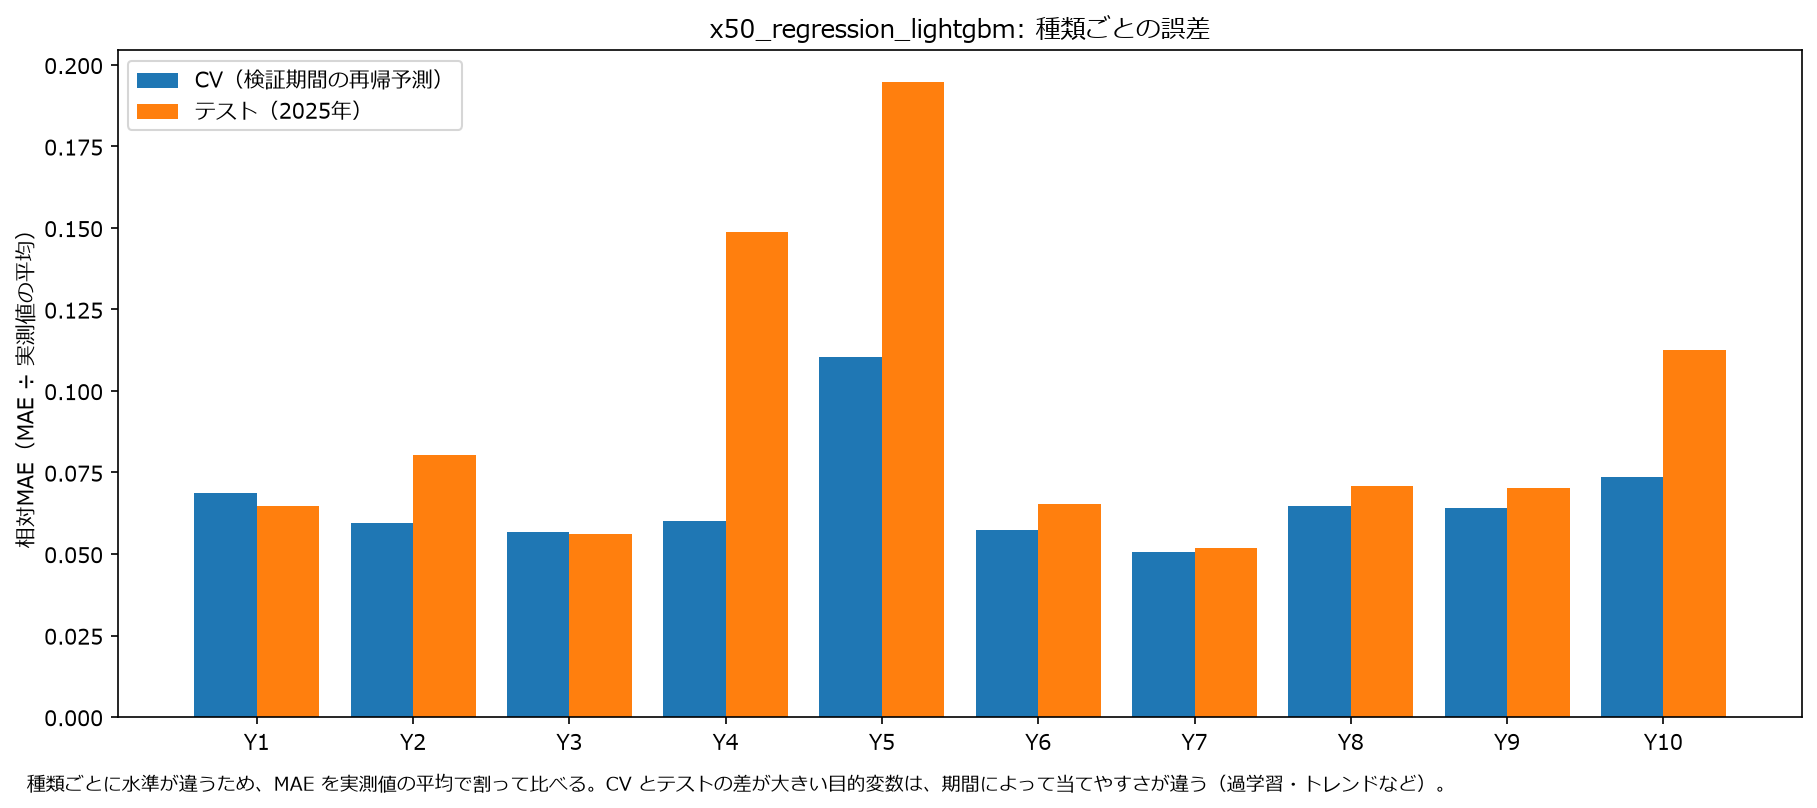

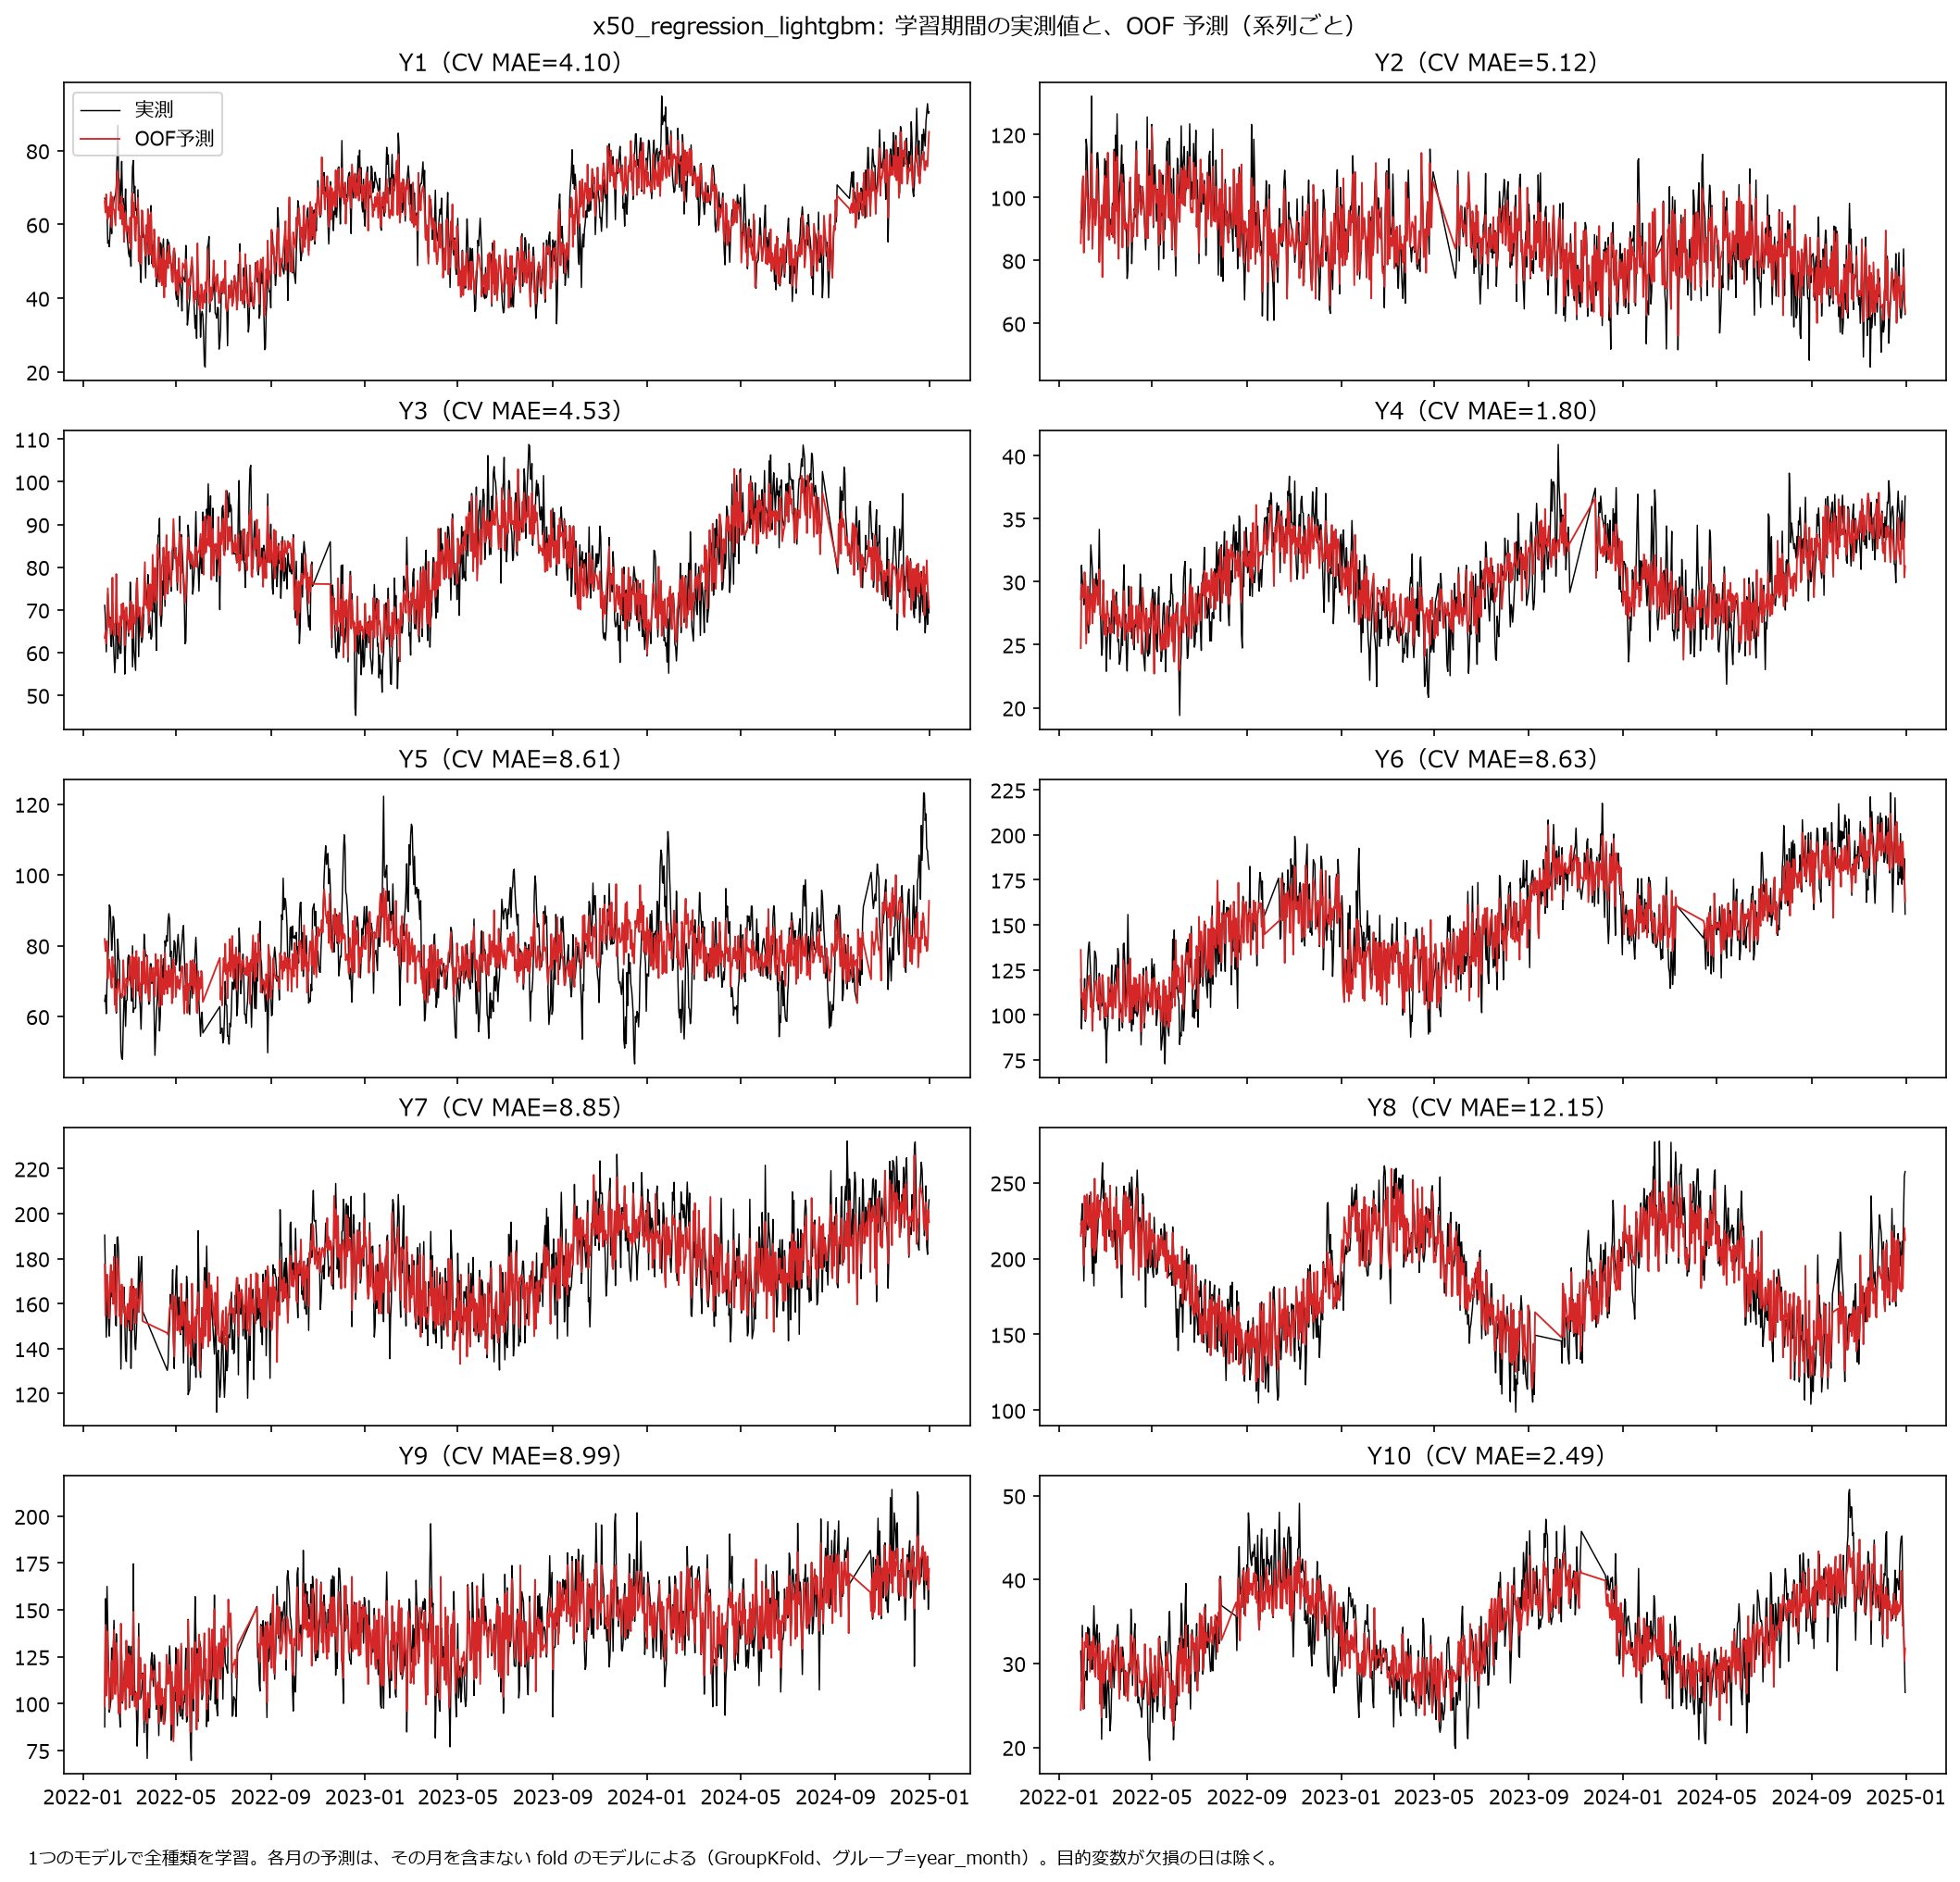

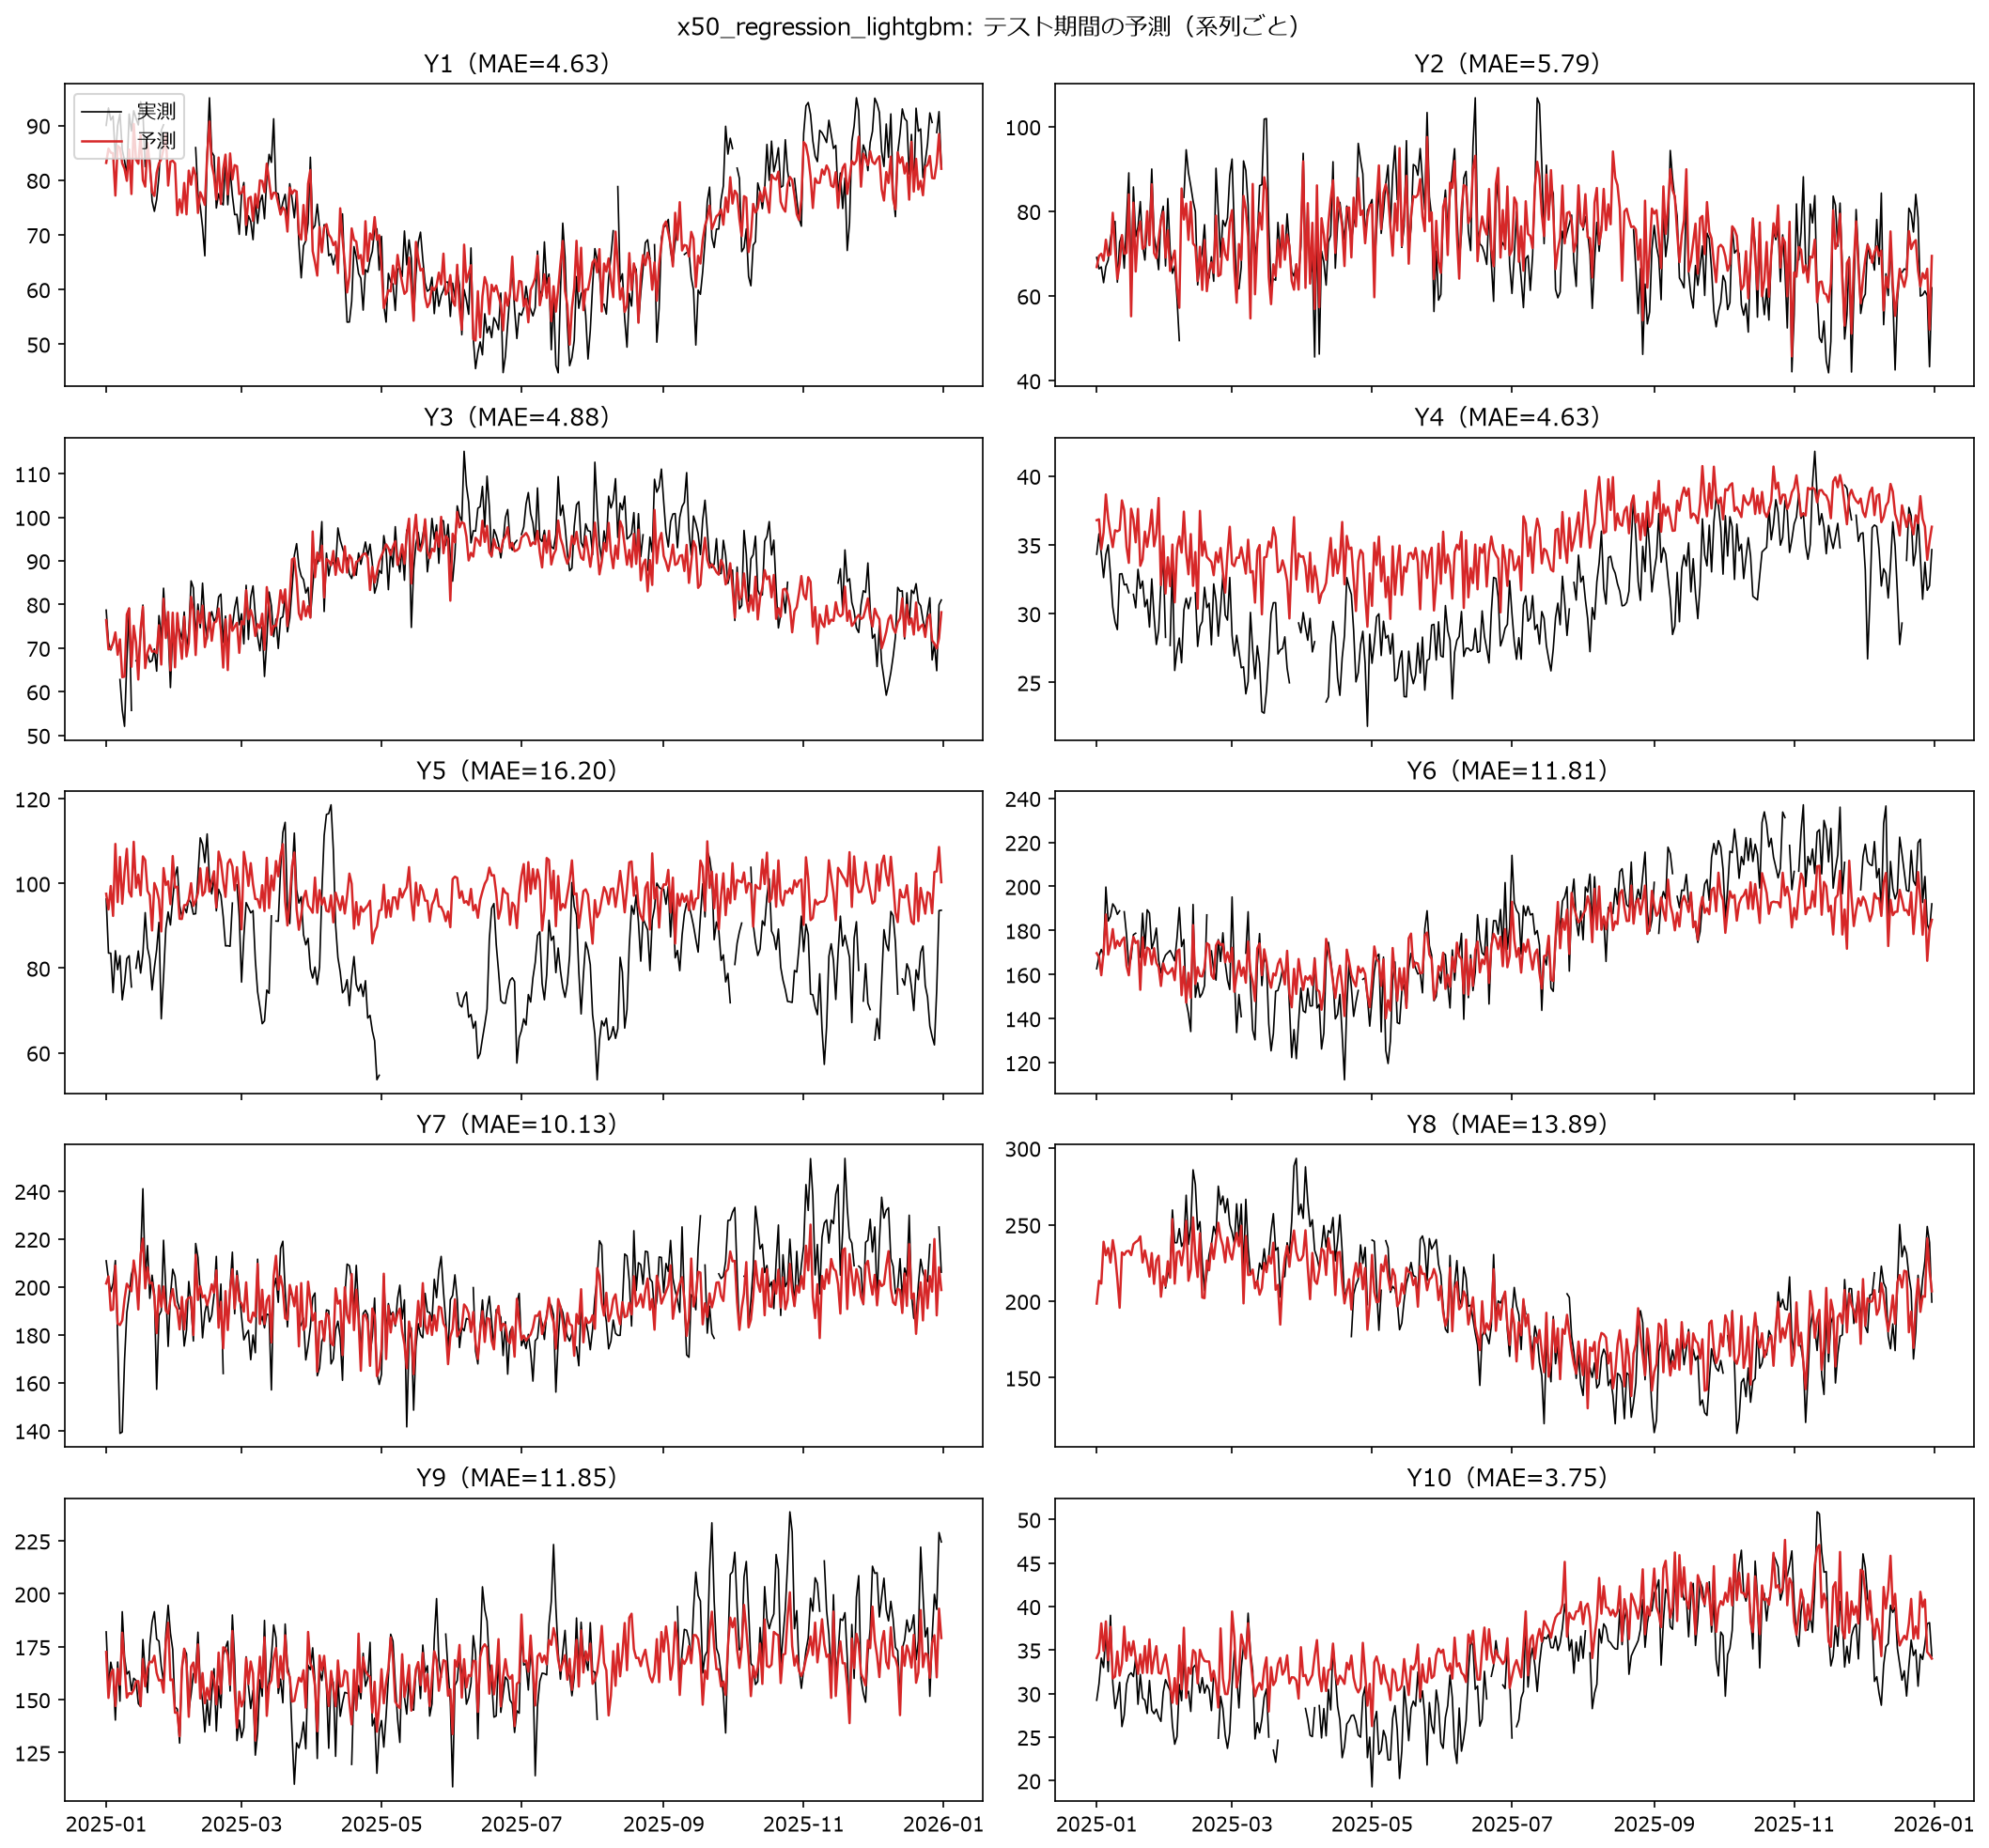

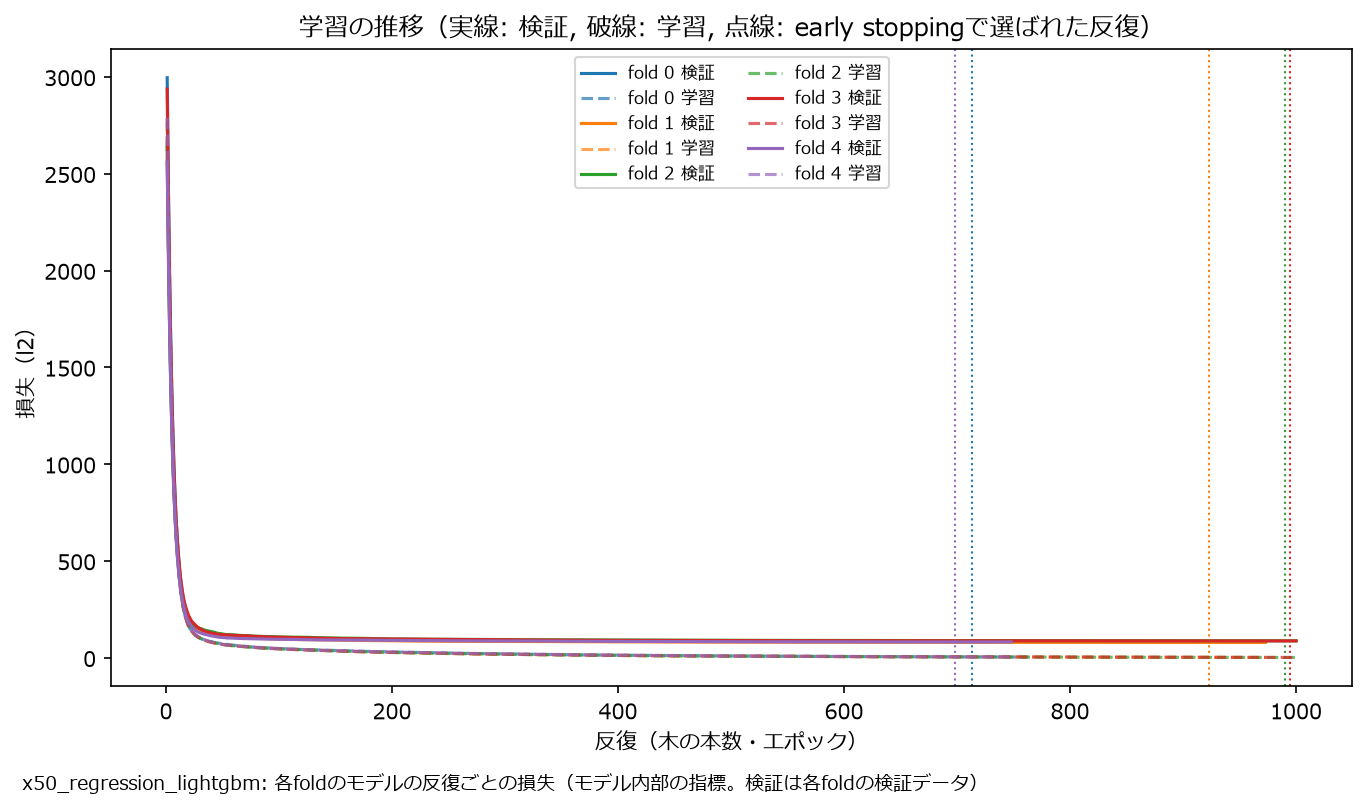

In [23]:
figures = out / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "training_overview.png"), width=1000))
display(Image(filename=str(figures / "test_overview.png"), width=1000))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

## 9. SHAP によるモデル解釈

モデルを、各 fold の検証側のデータで説明した SHAP 値（OOF SHAP）。目的変数を元の尺度で学習しているため、SHAP 値も元の尺度
（007 は対数の尺度）。

- **全体の重要度・beeswarm:** 全系列の行をまとめたもの。`Y_cat` は系列ID（どの種類か）。水準の違う種類を1つのモデルで
  予測するため、元の尺度では系列IDの寄与が大きくなりやすい。
- **種類ごとの重要度:** SHAP 値を行の系列で分けて平均し、種類ごとに合計1の割合にしたもの（004・007 の図と同じ形）。

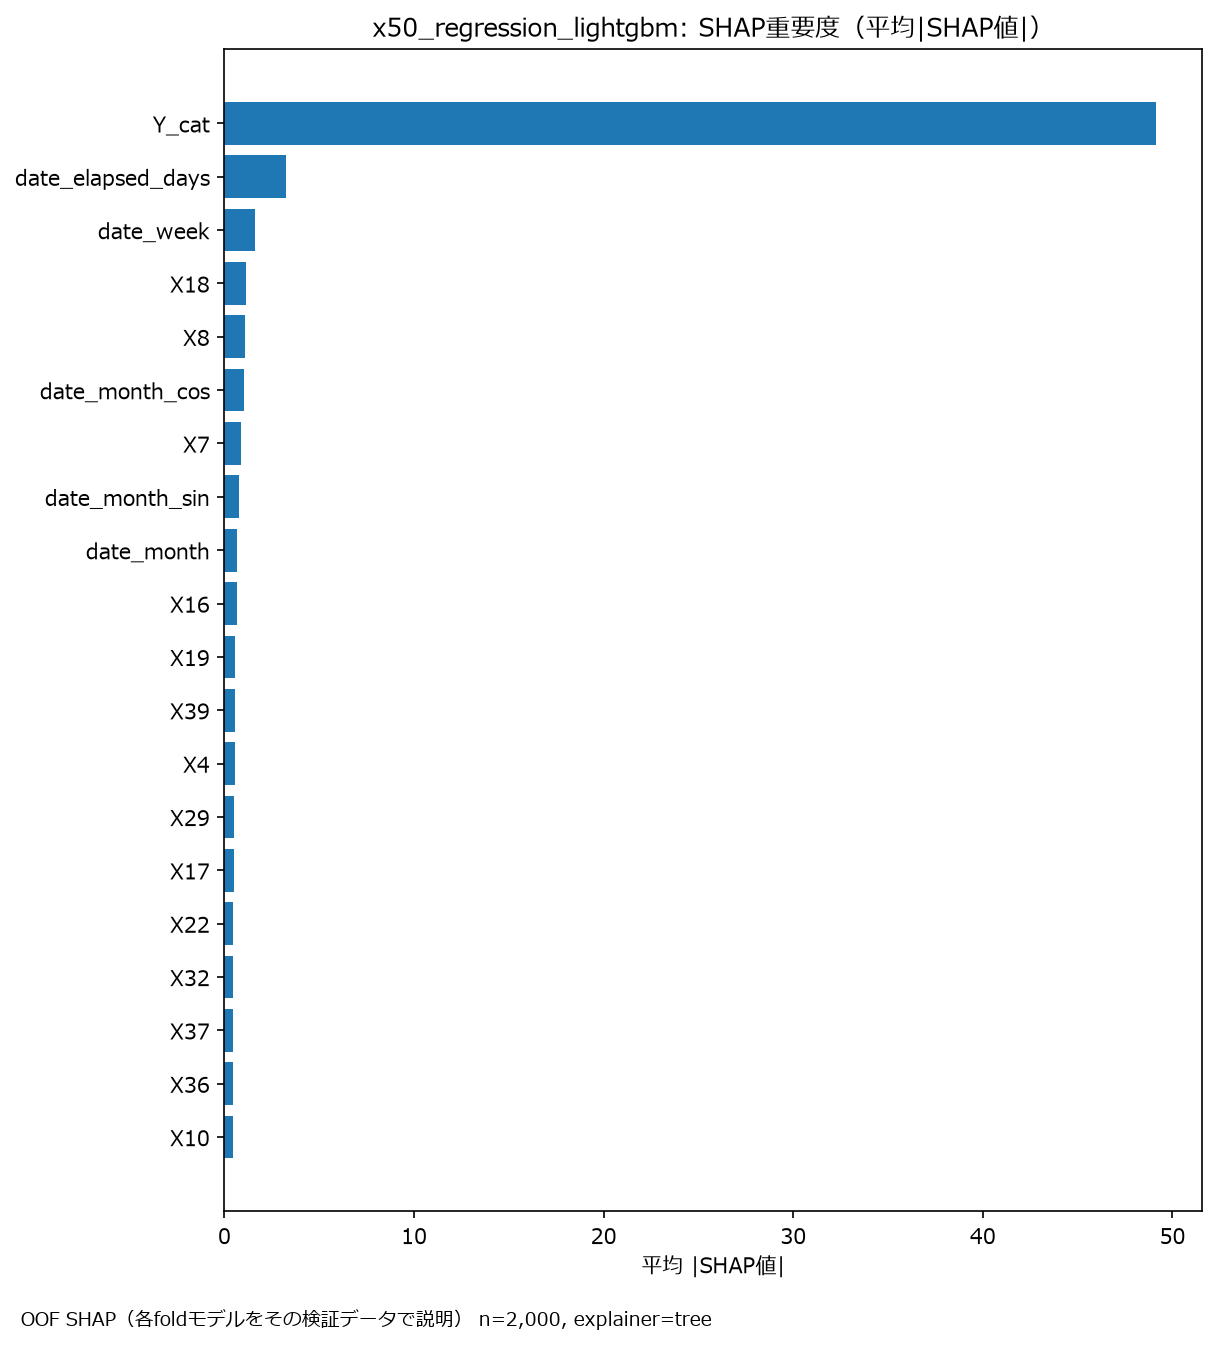

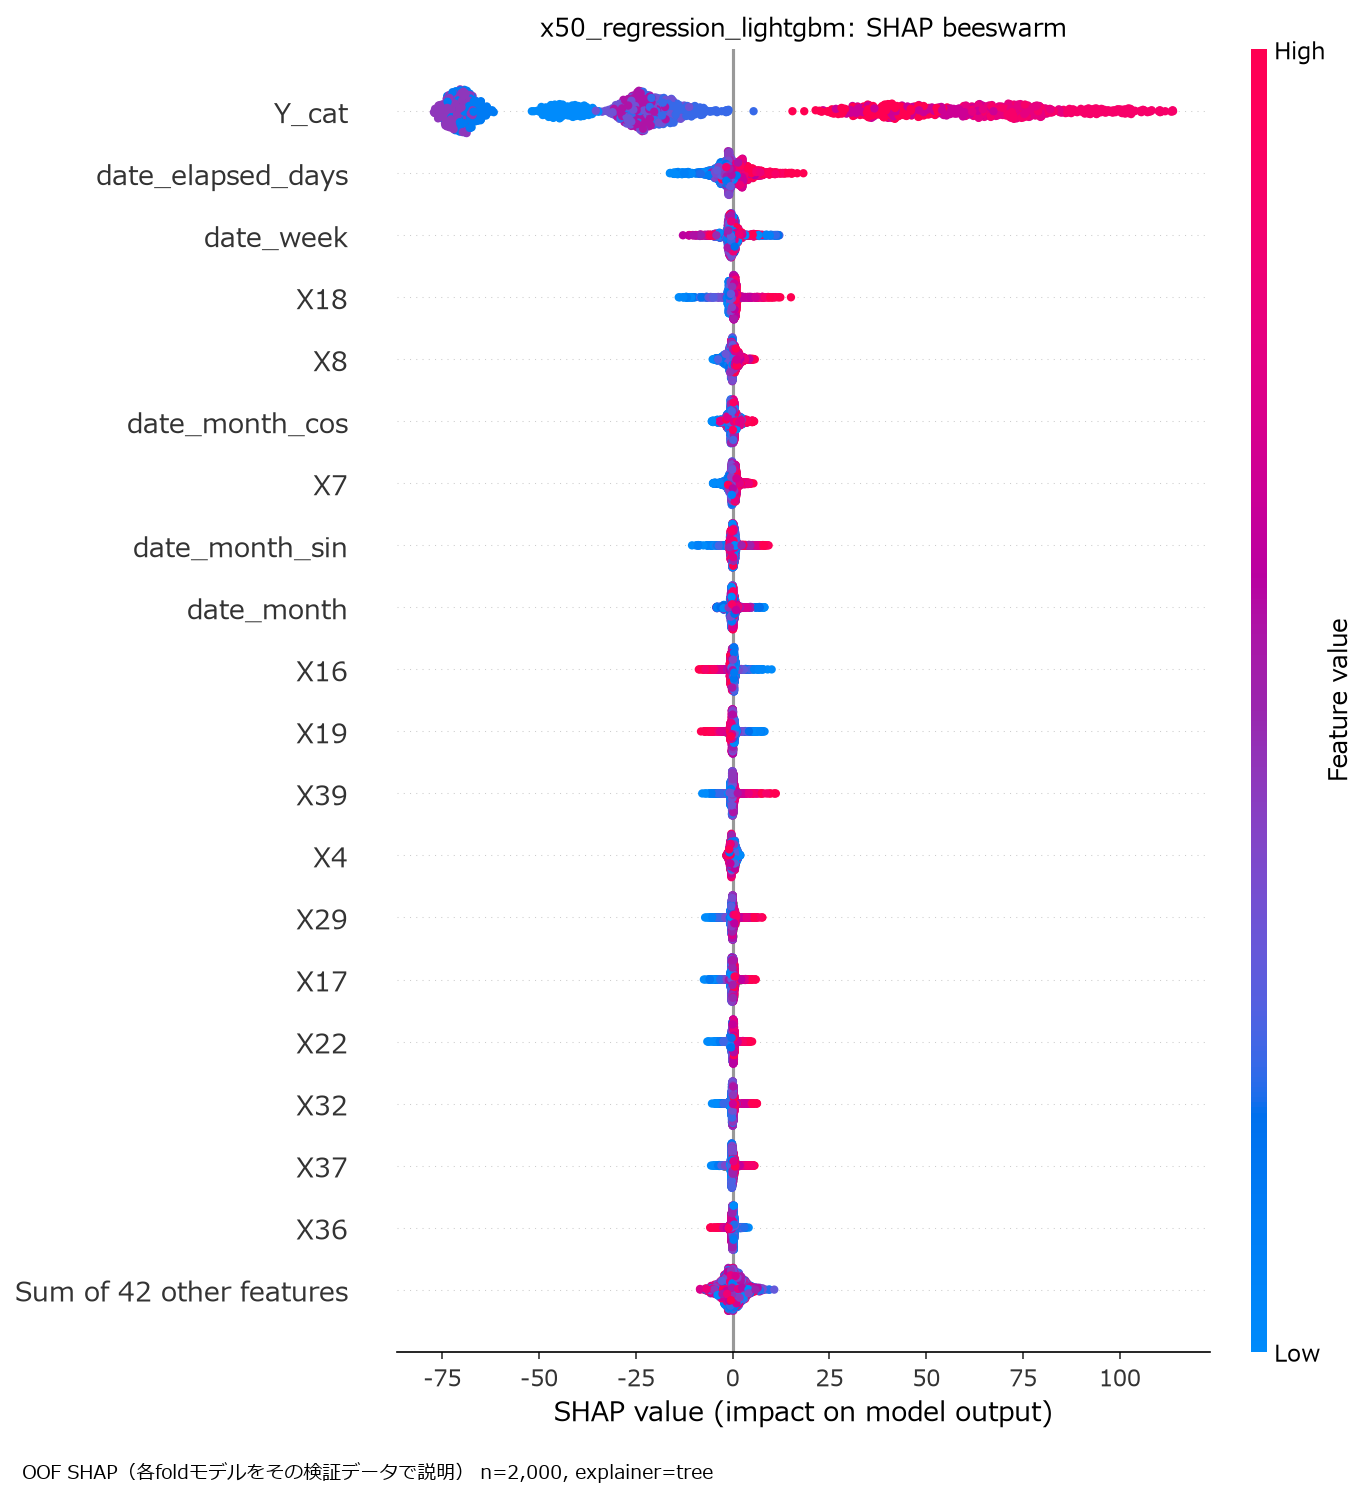

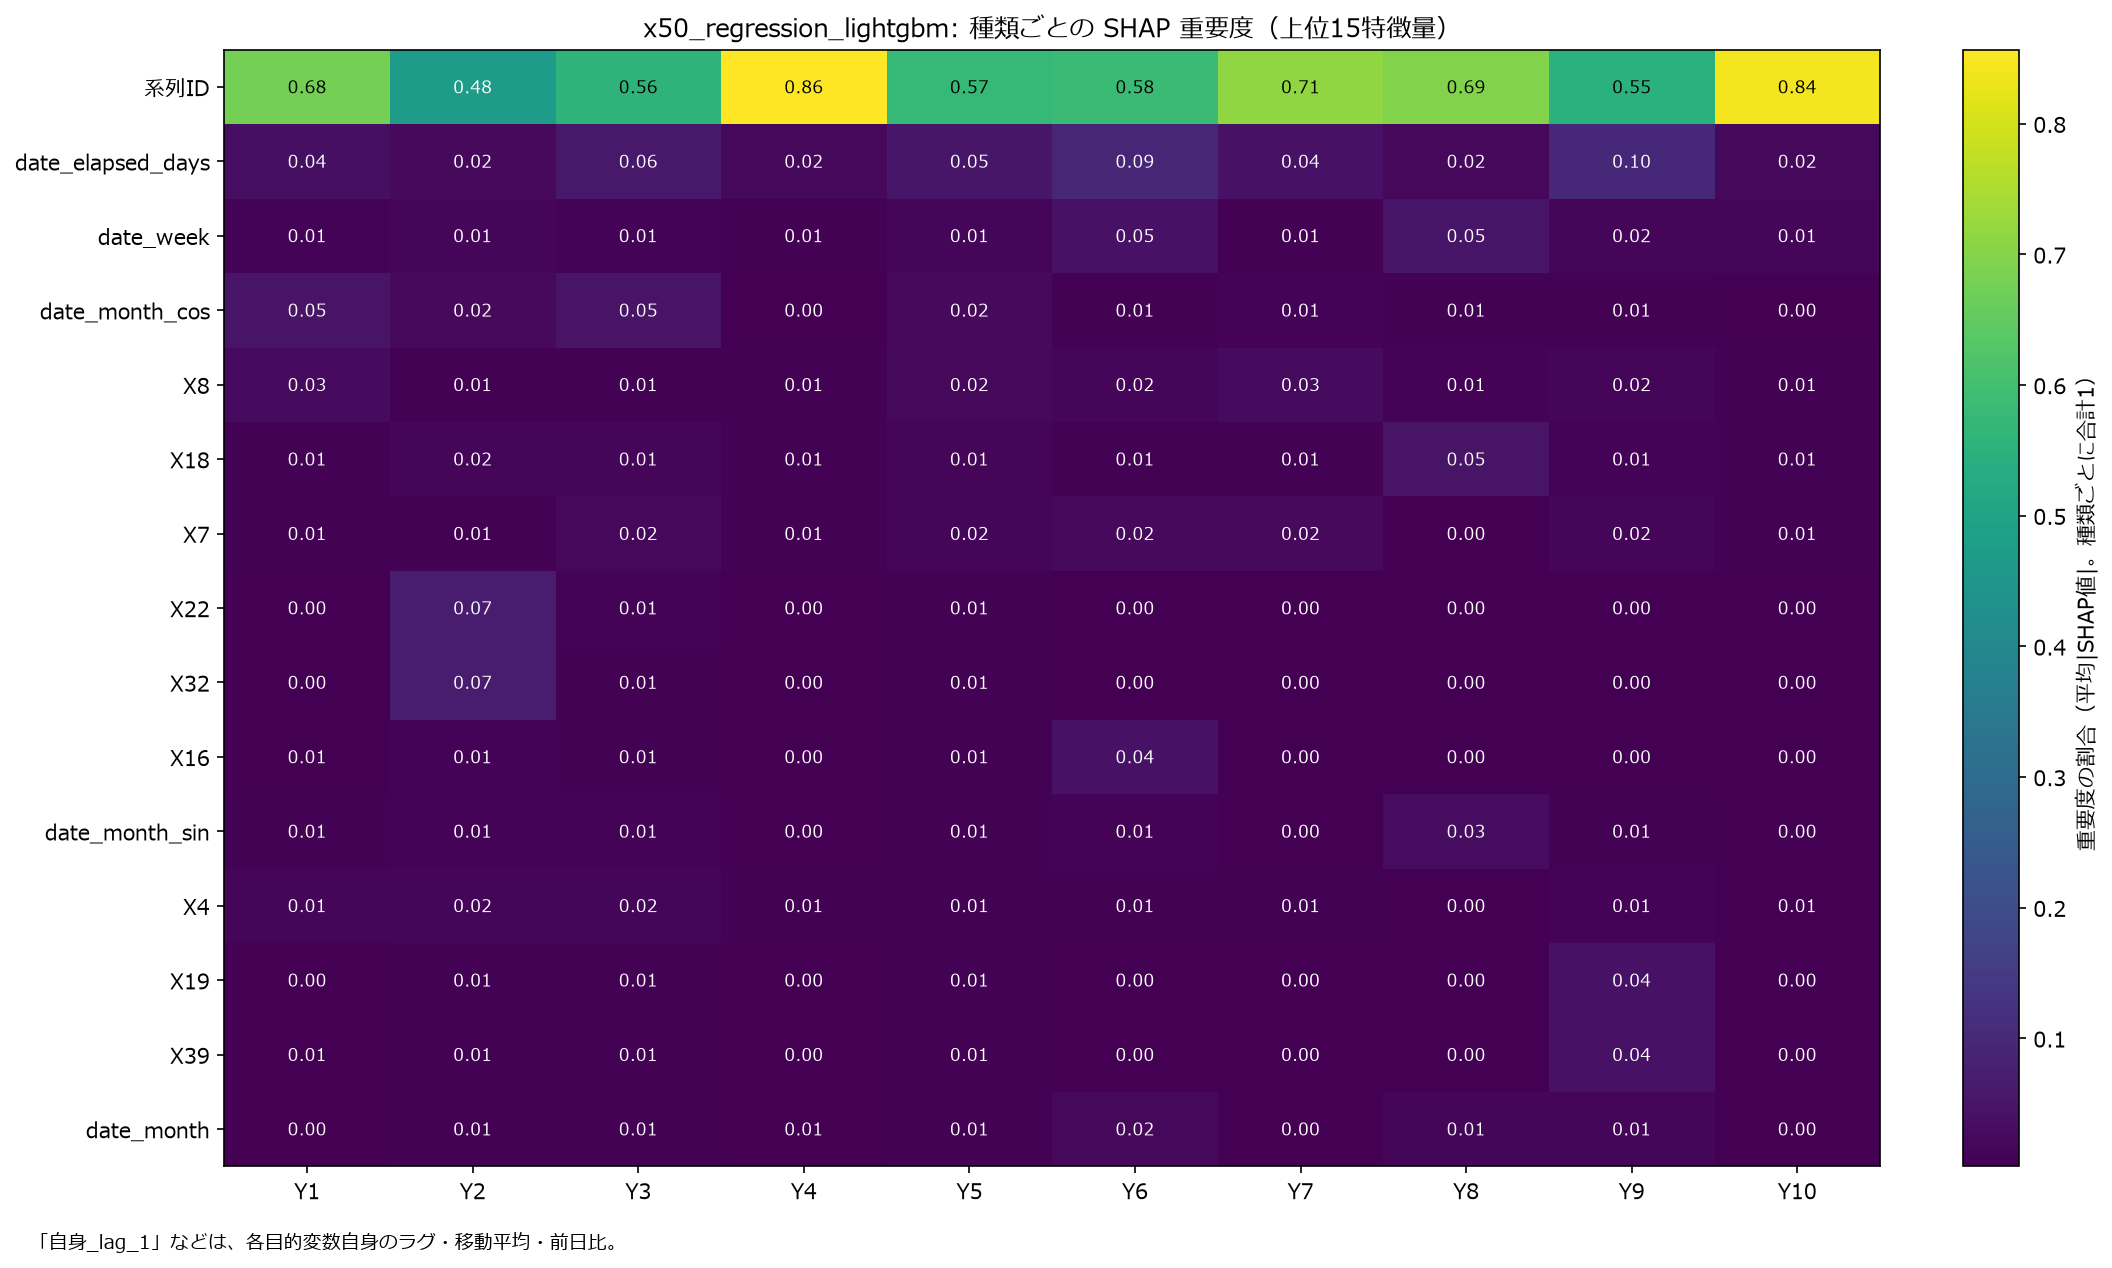

In [24]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(figures / "shap_overview.png"), width=1000))

## 10. 時系列モデル（004 / 006・005 / 007）との比較

同じモデルの最新の要約があれば、種類ごとの相対MAE を並べて比べる。

- 個別モデル（時系列）: `outputs/experiments/x50_{モデル名}_summary/` の最新（004・006）
- グローバルモデル（時系列）: `outputs/experiments/x50_global_{モデル名}/` の最新（005・007）
- 通常の回帰: このノートブックの結果

CV とテストの差も比べる（GroupKFold の CV が、テストに比べてどれだけ楽観的か）。

個別モデル（時系列）: outputs/experiments/x50_lightgbm_summary/20261025_233029/summary.csv
グローバル（時系列）: outputs/experiments/x50_global_lightgbm/20261025_234104_594654/summary.csv


,CV 相対MAE の平均,テスト 相対MAE の平均
通常の回帰（008）,0.0666,0.0915
個別モデル（時系列）,0.0728,0.0717
グローバル（時系列）,0.1013,0.1156


,通常の回帰（008）,個別モデル（時系列）,グローバル（時系列）
Y_cat,,,
Y1,0.0647,0.0545,0.1063
Y2,0.0803,0.0637,0.0988
Y3,0.0560,0.1847,0.2402
Y4,0.1488,0.0398,0.0465
Y5,0.1947,0.0838,0.2478
Y6,0.0653,0.0632,0.0973
Y7,0.0517,0.0415,0.0558
Y8,0.0708,0.0552,0.1150
Y9,0.0704,0.0691,0.0763


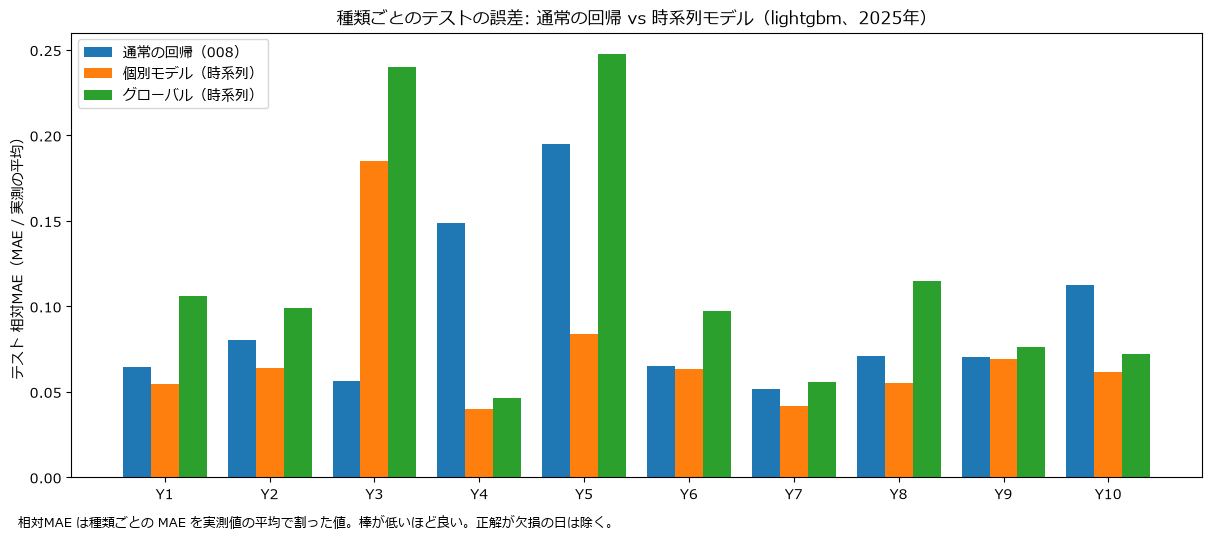

図: outputs/experiments/x50_regression_lightgbm/20261026_233218_886597/figures/comparison_with_time_series.png


In [25]:
experiments = outputs_dir() / "experiments"
sources = {
    "個別モデル（時系列）": experiments / f"x50_{MODEL}_summary",
    "グローバル（時系列）": experiments / f"x50_global_{MODEL}",
}
tables = {"通常の回帰（008）": summary}
if COMPARE_WITH_OTHERS:
    for label, directory in sources.items():
        found = sorted(directory.glob("*/summary.csv"))
        if found:
            tables[label] = pd.read_csv(found[-1])
            print(f"{label}: {shown(found[-1])}")
        else:
            print(f"{label}: 結果が無いため比べない（{shown(directory)}）")

metric = "test_relative_mae" if all("test_relative_mae" in t for t in tables.values()) else None
overview = pd.DataFrame(
    {
        label: {
            "CV 相対MAE の平均": float(t["cv_relative_mae"].mean()),
            "テスト 相対MAE の平均": float(t["test_relative_mae"].mean())
            if "test_relative_mae" in t
            else np.nan,
        }
        for label, t in tables.items()
    }
).T
display(overview.round(4))

if metric is not None and len(tables) > 1:
    comparison = pd.DataFrame(
        {label: t.set_index(CAT_COL)[metric] for label, t in tables.items()}
    ).loc[inputs.categories]
    display(comparison.round(4))
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(comparison))
    width = 0.8 / comparison.shape[1]
    for k, label in enumerate(comparison.columns):
        ax.bar(
            positions + (k - (comparison.shape[1] - 1) / 2) * width,
            comparison[label],
            width,
            label=label,
        )
    ax.set_xticks(positions, comparison.index)
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("テスト 相対MAE（MAE / 実測の平均）")
    ax.set_title(f"種類ごとのテストの誤差: 通常の回帰 vs 時系列モデル（{MODEL}、2025年）")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "相対MAE は種類ごとの MAE を実測値の平均で割った値。棒が低いほど良い。"
        "正解が欠損の日は除く。",
    )
    comparison_path = figures / "comparison_with_time_series.png"
    fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"図: {shown(comparison_path)}")

## 11. 1つの種類の詳細（`DETAIL_TARGET`）

`DETAIL_TARGET` の学習期間の OOF 予測（fold ごとに色分け。各月は、その月を含まない fold のモデルの予測）と、
テスト期間の予測を実測と並べる。全系列をまとめた残差の図（`modeling.evaluation`）も表示する。

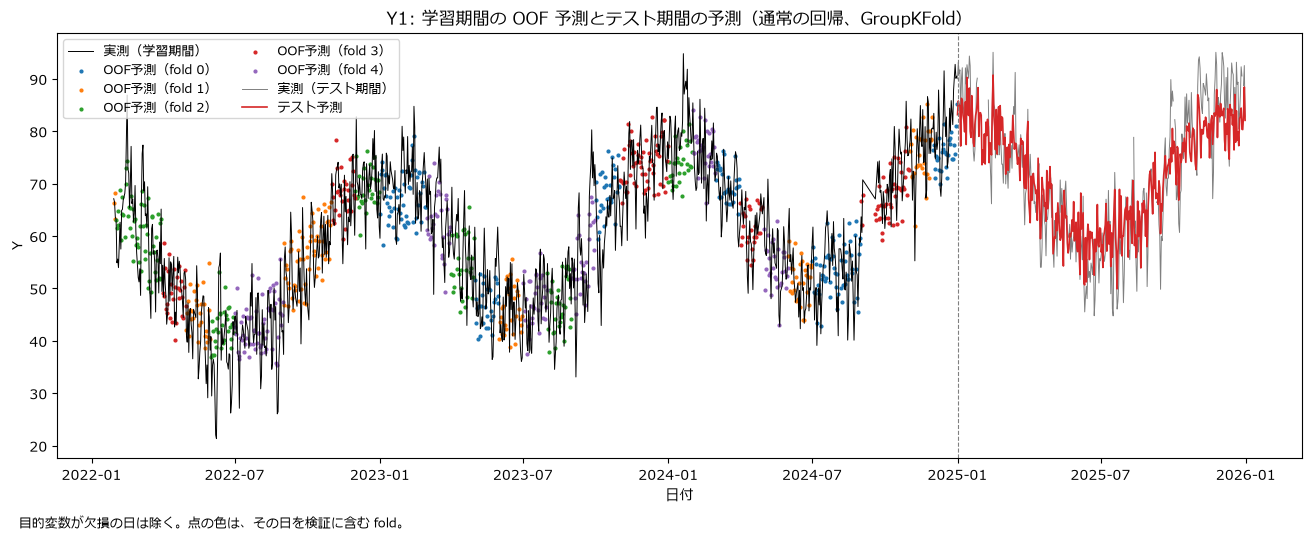

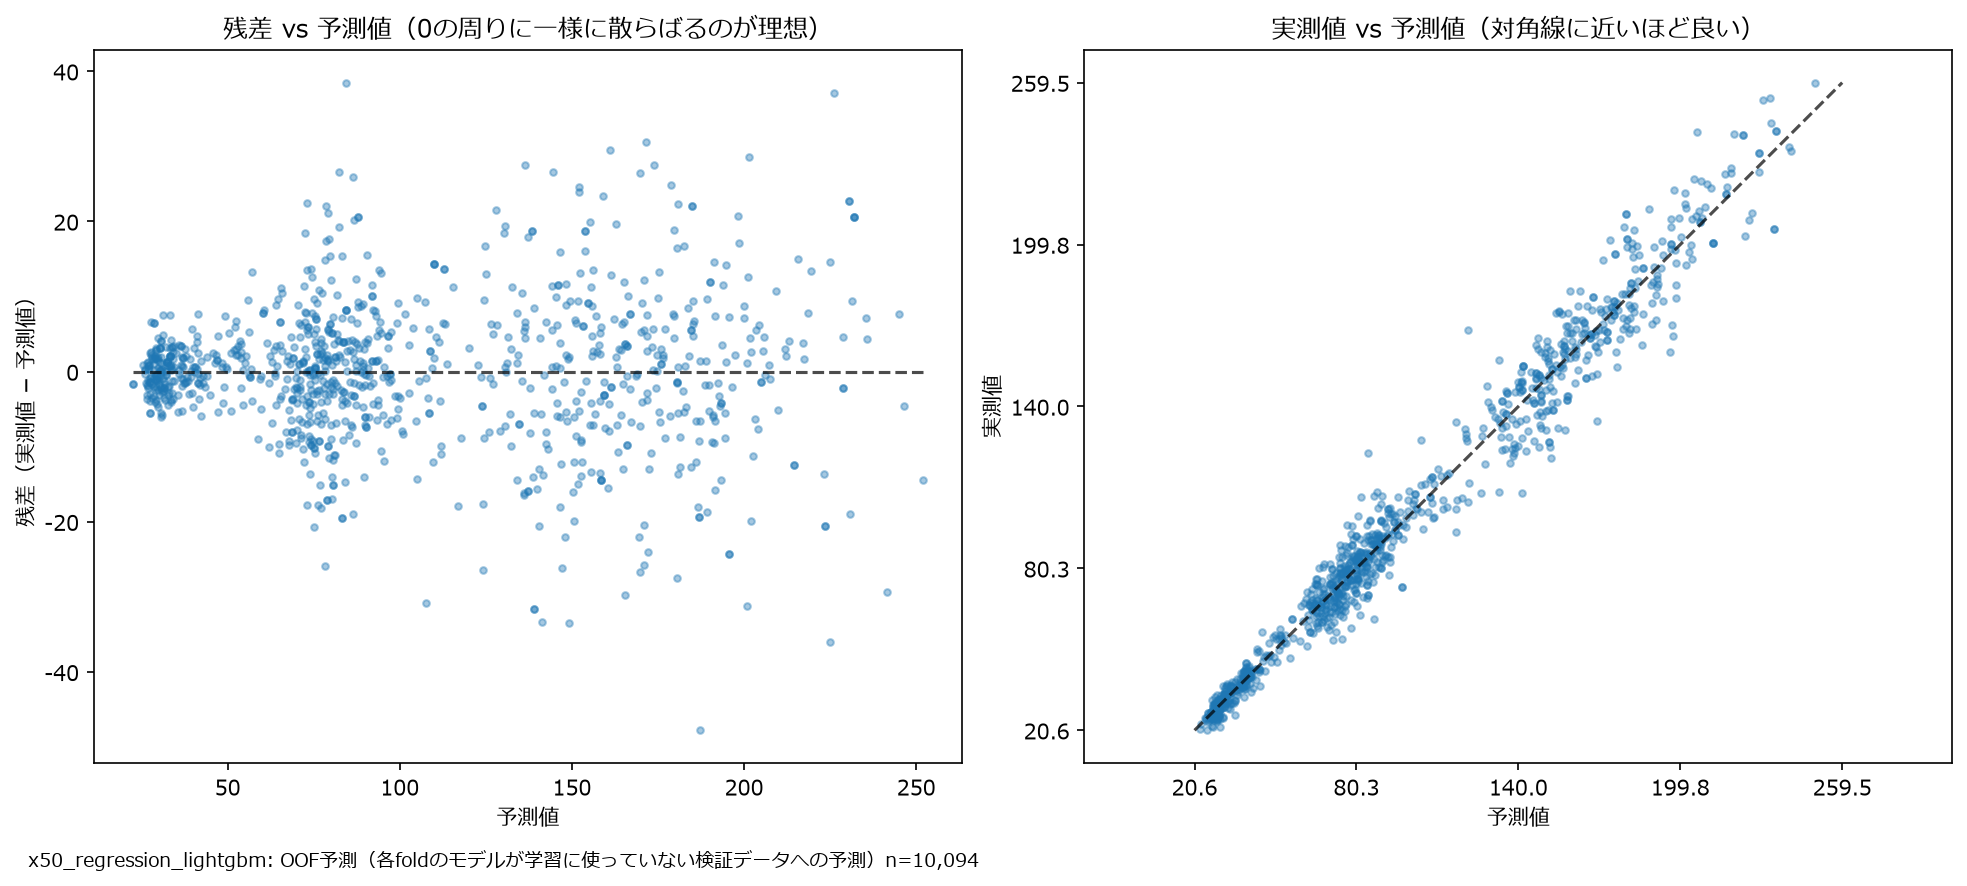

,date,Y_cat,pred,actual
0,2025-01-01,Y1,83.147267,90.004803
10,2025-01-02,Y1,85.770200,93.198048
20,2025-01-03,Y1,85.031231,90.977363
30,2025-01-04,Y1,84.900997,91.699246
40,2025-01-05,Y1,77.171621,84.084049


In [26]:
ensure_japanese_font()
oof_detail = run.oof[run.oof[CAT_COL] == DETAIL_TARGET]
test_detail = run.predictions[run.predictions[CAT_COL] == DETAIL_TARGET]
fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
ax.plot(
    oof_detail[DATE_COL],
    oof_detail[ACTUAL_COL],
    color="black",
    linewidth=0.7,
    label="実測（学習期間）",
)
for fold in sorted(oof_detail["fold"].unique()):
    part = oof_detail[oof_detail["fold"] == fold]
    ax.scatter(
        part[DATE_COL], part[PRED_COL], s=4, color=f"C{fold}", label=f"OOF予測（fold {fold}）"
    )
if ACTUAL_COL in test_detail.columns:
    ax.plot(
        test_detail[DATE_COL],
        test_detail[ACTUAL_COL],
        color="gray",
        linewidth=0.7,
        label="実測（テスト期間）",
    )
ax.plot(test_detail[DATE_COL], test_detail[PRED_COL], color="C3", linewidth=1.2, label="テスト予測")
ax.axvline(test_detail[DATE_COL].min(), color="gray", linestyle="--", linewidth=0.8)
ax.set_title(f"{DETAIL_TARGET}: 学習期間の OOF 予測とテスト期間の予測（通常の回帰、GroupKFold）")
ax.set_xlabel("日付")
ax.set_ylabel(TARGET_COL)
ax.legend(loc="upper left", ncol=2, fontsize=9)
add_caption(fig, "目的変数が欠損の日は除く。点の色は、その日を検証に含む fold。")
plt.show()
plt.close(fig)
display(Image(filename=str(out / "evaluation" / "residual_plot.png"), width=700))
test_detail.head()

## まとめ

- 前半は 007 と同じ前処理で、前処理済みの CSV（long 型）を出力した。
- 後半で、時系列として扱わず、通常の回帰として全種類を1つのモデルで学習・予測した。特徴量は系列ID・日付の特徴量・
  説明変数だけで、目的変数のラグは使っていない（テスト期間には作れないため）。各行の予測は、その行の特徴量だけから行う
  （予測のリークの確認で確認）。
- CV は年月をグループにした GroupKFold で、同じ月の行が学習と検証に分かれないことを確かめた。
- ログはファイル（`outputs/logs/`、出力ディレクトリの `run.log`）と MLflow（全体・種類ごとの MAE、図、予測）に残している。

**注意点**

- GroupKFold では検証の月より後の月も学習に使うため、CV はテスト（学習データより後の2025年）より楽観的になりやすい。
  時間の流れに沿った評価が必要なら、007 の時系列CV（`time_cutoff`）を使う。
- 目的変数のラグを使わないため、目的変数自身の自己相関（前日の値に近い）を予測に使えない。説明変数・日付から説明できない
  変動は予測できない。トレンドのある種類（ダミーでは Y3・Y6・Y9）は、日付の特徴量の範囲外（2025年）への外挿が苦手。
- 目的変数を元の尺度で学習しているため、早期終了の指標（MAE）は水準の高い種類の誤差の影響が大きい。
- 目的変数が欠損の行は学習・評価から除いている。説明変数の欠損は LightGBM / XGBoost の欠損の扱いに任せている。
- SHAP は検証側（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使ったデータが違う。